In [2]:
import numpy as np
import scipy
import pandas as pd
import networkx as nx
import geopandas as gpd
import wntr

In [3]:
import os

os.chdir("/Users/vb/Desktop/MASTER_THESIS/MOO_OPT/NYT_validation")

print("Current working directory:", os.getcwd())

Current working directory: /Users/vb/Desktop/MASTER_THESIS/MOO_OPT/NYT_validation


In [5]:
# ============================================================
# NOTEBOOK 4
# FULL FLEXIBLE SCENARIO-TREE OPTIMIZATION - NYT
#
# ============================================================
#
# SCENARIO TREE
#
#                         YEAR 15
#                    COMMON INITIAL
#                    REHABILITATION
#                           |
#             ┌─────────────┼─────────────┐
#             |             |             |
#            -5%           +5%           +7%
#          YEAR 30       YEAR 30       YEAR 30
#             |             |             |
#           ┌─┴─┐         ┌─┴─┐         ┌─┴─┐
#          -10 +7        +10 +12        +5  +3
#          Y50  Y50      Y50  Y50       Y50 Y50
#
#
# YEAR 15:
#     Fixed common rehabilitation obtained from
#     the three independent pathway optimizations.
#
# YEAR 30:
#     3 independent branch decisions.
#
# YEAR 50:
#     6 independent leaf decisions.
#
#
# IMPORTANT:
#
# The optimization variables are NOT absolute pipe options.
#
# They represent ADDITIONAL rehabilitation increments.
#
# Therefore:
#
# Actual Year 30 = Year 15 + Year 30 increment
#
# Actual Year 50 = Year 30 + Year 50 increment
#
# This guarantees:
#
# Year 15 <= Year 30 <= Year 50
#
# for every pipe and every pathway.
#
# ============================================================


import numpy as np
import wntr
import copy

from pymoo.core.problem import ElementwiseProblem
from pymoo.core.sampling import Sampling
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.optimize import minimize


# ============================================================
# 1. FULL TREE FLEXIBLE OPTIMIZATION PROBLEM
# ============================================================

class NYTFullTreeFlexibleProblem(ElementwiseProblem):


    # ========================================================
    # INITIALIZATION
    # ========================================================

    def __init__(self, inp_file):


        self.inp_file = inp_file


        # ====================================================
        # REHABILITATION DIAMETER OPTIONS
        # ====================================================

        self.parallel_diameters_in = np.array([

            0,
            36,
            48,
            60,
            72,
            84,
            96,
            108,
            120,
            132,
            144,
            156,
            168,
            180,
            192,
            204

        ])


        # ====================================================
        # LOAD NETWORK
        # ====================================================

        wn_temp = wntr.network.WaterNetworkModel(

            self.inp_file

        )


        # ====================================================
        # CANDIDATE PIPES
        # ====================================================

        self.pipe_names = list(

            wn_temp.pipe_name_list

        )

        self.n_pipes = len(

            self.pipe_names

        )


        print(

            "Number of candidate pipes =",

            self.n_pipes

        )


        # ====================================================
        # REQUIRED HEADS
        # ====================================================

        self.required_head_ft = {

            '2': 255.0,
            '3': 255.0,
            '4': 255.0,
            '5': 255.0,
            '6': 255.0,
            '7': 255.0,
            '8': 255.0,
            '9': 255.0,
            '10': 255.0,
            '11': 255.0,
            '12': 255.0,
            '13': 255.0,
            '14': 255.0,
            '15': 255.0,
            '16': 260.0,
            '17': 272.8,
            '18': 255.0,
            '19': 255.0,
            '20': 255.0

        }


        # Convert ft → m

        self.required_head_m = {

            k: v * 0.3048

            for k, v in self.required_head_ft.items()

        }


        # ====================================================
        # PLANNING YEARS
        # ====================================================

        self.year_15 = 15
        self.year_30 = 30
        self.year_50 = 50


        # ====================================================
        # COMMON YEAR-15 DECISION
        # ====================================================
        #
        # Obtained from the three independent pathway runs.
        #
        # THIS IS FIXED.
        #
        # ====================================================

        self.year15_common = np.array([

            0,
            7,
            0,
            0,
            0,
            0,
            9,
            0,
            0,
            0,
            0,
            6,
            9,
            4,
            8,
            5,
            9,
            7,
            6,
            0,
            6

        ], dtype=int)


        if len(self.year15_common) != self.n_pipes:

            raise ValueError(

                "Year-15 common decision has a different "
                "number of pipes than the network."

            )


        # ====================================================
        # DEMAND SCENARIO TREE
        # ====================================================
        #
        # Demand changes are SUCCESSIVE.
        #
        # Pathway 1:
        #
        # 1.00 → 0.95 → 0.855
        #
        # 1.00 → 0.95 → 1.0165
        #
        #
        # Pathway 2:
        #
        # 1.00 → 1.05 → 1.155
        #
        # 1.00 → 1.05 → 1.176
        #
        #
        # Pathway 3:
        #
        # 1.00 → 1.07 → 1.1235
        #
        # 1.00 → 1.07 → 1.1021
        #
        # ====================================================

        self.factor_Y30_A = 0.95
        self.factor_Y30_B = 1.05
        self.factor_Y30_C = 1.07


        self.factor_Y50_A1 = (

            self.factor_Y30_A * 0.90

        )

        self.factor_Y50_A2 = (

            self.factor_Y30_A * 1.07

        )


        self.factor_Y50_B1 = (

            self.factor_Y30_B * 1.10

        )

        self.factor_Y50_B2 = (

            self.factor_Y30_B * 1.12

        )


        self.factor_Y50_C1 = (

            self.factor_Y30_C * 1.05

        )

        self.factor_Y50_C2 = (

            self.factor_Y30_C * 1.03

        )


        print("\nDemand scenario factors:")

        print(

            "Pathway 1:",

            self.factor_Y30_A,

            "→",

            self.factor_Y50_A1,

            "or",

            self.factor_Y50_A2

        )


        print(

            "Pathway 2:",

            self.factor_Y30_B,

            "→",

            self.factor_Y50_B1,

            "or",

            self.factor_Y50_B2

        )


        print(

            "Pathway 3:",

            self.factor_Y30_C,

            "→",

            self.factor_Y50_C1,

            "or",

            self.factor_Y50_C2

        )


        # ====================================================
        # SCENARIO PROBABILITIES
        # ====================================================

        self.weight_Y30_A = 1.0 / 3.0
        self.weight_Y30_B = 1.0 / 3.0
        self.weight_Y30_C = 1.0 / 3.0


        self.weight_Y50_A1 = 1.0 / 6.0
        self.weight_Y50_A2 = 1.0 / 6.0

        self.weight_Y50_B1 = 1.0 / 6.0
        self.weight_Y50_B2 = 1.0 / 6.0

        self.weight_Y50_C1 = 1.0 / 6.0
        self.weight_Y50_C2 = 1.0 / 6.0


        # ====================================================
        # DISCOUNT RATE
        # ====================================================

        self.discount_rate = 0.04


        # ====================================================
        # NUMBER OF OPTIMIZATION VARIABLES
        # ====================================================
        #
        # We optimize INCREMENTS:
        #
        # Year 30:
        #
        #   A increment = 21
        #   B increment = 21
        #   C increment = 21
        #
        # Year 50:
        #
        #   A1 increment = 21
        #   A2 increment = 21
        #   B1 increment = 21
        #   B2 increment = 21
        #   C1 increment = 21
        #   C2 increment = 21
        #
        # Total:
        #
        # 9 × 21 = 189 variables
        #
        # ====================================================

        self.n_variables = (

            9 * self.n_pipes

        )


        # ====================================================
        # HYDRAULIC CONSTRAINTS
        # ====================================================
        #
        # We evaluate:
        #
        # Year 15
        # 3 × Year 30
        # 6 × Year 50
        #
        # = 10 network states.
        #
        # Each state has one head constraint for each
        # required-head node.
        #
        # ====================================================

        n_hydraulic_constraints = (

            10
            *
            len(self.required_head_m)

        )


        # ====================================================
        # PYMOO PROBLEM
        # ====================================================
        #
        # There are NO monotonicity constraints here.
        #
        # Why?
        #
        # Because the chromosome itself consists only of
        # non-negative rehabilitation increments.
        #
        # Therefore monotonicity is guaranteed structurally.
        #
        # ====================================================

        super().__init__(

            n_var=self.n_variables,

            n_obj=2,

            n_ieq_constr=n_hydraulic_constraints,

            xl=0,

            xu=len(

                self.parallel_diameters_in

            ) - 1,

            vtype=int

        )


    # ========================================================
    # ORIGINAL DEMANDS
    # ========================================================

    def get_original_demands(self, wn):


        original_demands = {}


        for node_name in wn.junction_name_list:


            node = wn.get_node(

                node_name

            )


            original_demands[node_name] = []


            for demand in (

                node.demand_timeseries_list

            ):


                original_demands[node_name].append(

                    demand.base_value

                )


        return original_demands


    # ========================================================
    # APPLY DEMAND FACTOR
    # ========================================================

    def apply_demand_factor(

        self,
        wn,
        original_demands,
        factor

    ):


        for node_name in wn.junction_name_list:


            node = wn.get_node(

                node_name

            )


            for j, demand in enumerate(

                node.demand_timeseries_list

            ):


                demand.base_value = (

                    original_demands[node_name][j]
                    *
                    factor

                )


    # ========================================================
    # APPLY REHABILITATION
    # ========================================================
    #
    # stage_x contains ABSOLUTE rehabilitation options.
    #
    # Example:
    #
    # option = 7
    #
    # means the current rehabilitation pipe has
    # diameter option 7.
    #
    # ========================================================

    def apply_rehabilitation(

        self,
        wn,
        stage_x

    ):


        for i, pipe_name in enumerate(

            self.pipe_names

        ):


            option = int(

                round(stage_x[i])

            )


            option = np.clip(

                option,

                0,

                len(
                    self.parallel_diameters_in
                ) - 1

            )


            # No rehabilitation

            if option == 0:

                continue


            diameter_in = (

                self.parallel_diameters_in[option]

            )


            original_pipe = wn.get_link(

                pipe_name

            )


            parallel_name = (

                f"{pipe_name}_parallel"

            )


            # Remove previous rehabilitation pipe
            # before replacing it with the new larger
            # rehabilitation pipe.

            if parallel_name in wn.link_name_list:

                wn.remove_link(

                    parallel_name

                )


            # Add rehabilitation pipe

            wn.add_pipe(

                parallel_name,

                original_pipe.start_node_name,

                original_pipe.end_node_name,

                length=original_pipe.length,

                diameter=(

                    diameter_in
                    *
                    0.0254

                ),

                roughness=original_pipe.roughness

            )


    # ========================================================
    # CONVERT INCREMENT → ABSOLUTE OPTION
    # ========================================================
    #
    # THIS IS THE IMPORTANT FIX.
    #
    # previous_x = rehabilitation already installed
    #
    # increment_x = additional rehabilitation selected by
    #               NSGA-II
    #
    # actual_x = previous_x + increment_x
    #
    # Therefore actual_x can NEVER be smaller than
    # previous_x.
    #
    # ========================================================

    def apply_increment(

        self,
        previous_x,
        increment_x

    ):


        previous_x = np.asarray(

            previous_x,

            dtype=int

        )


        increment_x = np.asarray(

            increment_x,

            dtype=int

        )


        actual_x = (

            previous_x
            +
            increment_x

        )


        # Maximum available rehabilitation option

        max_option = (

            len(
                self.parallel_diameters_in
            )
            -
            1

        )


        actual_x = np.clip(

            actual_x,

            0,

            max_option

        )


        return actual_x.astype(int)


    # ========================================================
    # RESILIENCE
    # ========================================================

    def calculate_resilience(

        self,
        wn,
        results

    ):


        heads = (

            results
            .node["head"]
            .iloc[0]

        )


        demands = (

            results
            .node["demand"]
            .iloc[0]

        )


        # ----------------------------------------------------
        # Ui
        # ----------------------------------------------------

        Ui = {}


        for node_name in (

            self.required_head_m.keys()

        ):


            connected_diameters = []


            for link_name in wn.pipe_name_list:


                pipe = wn.get_link(

                    link_name

                )


                if (

                    pipe.start_node_name == node_name

                    or

                    pipe.end_node_name == node_name

                ):


                    connected_diameters.append(

                        pipe.diameter
                        /
                        0.0254

                    )


            if len(

                connected_diameters

            ) > 0:


                sumDiameter = np.sum(

                    connected_diameters

                )


                maxDiameter = np.max(

                    connected_diameters

                )


                nPipe = len(

                    connected_diameters

                )


                Ui[node_name] = (

                    sumDiameter
                    /
                    (
                        nPipe
                        *
                        maxDiameter
                    )

                )


            else:

                Ui[node_name] = 0.0


        # ----------------------------------------------------
        # X
        # ----------------------------------------------------

        X = 0.0

        Xmax = 0.0


        for node_name in (

            self.required_head_m.keys()

        ):


            X += (

                Ui[node_name]
                *
                demands[node_name]
                *
                (
                    heads[node_name]
                    -
                    self.required_head_m[node_name]
                )

            )


            Xmax -= (

                demands[node_name]
                *
                self.required_head_m[node_name]

            )


        # ----------------------------------------------------
        # Reservoir
        # ----------------------------------------------------

        reservoir_name = (

            wn.reservoir_name_list[0]

        )


        reservoir_head = (

            heads[reservoir_name]

        )


        reservoir_discharge = (

            demands[reservoir_name]

        )


        Xmax += (

            -reservoir_discharge
            *
            reservoir_head

        )


        # ----------------------------------------------------
        # Resilience
        # ----------------------------------------------------

        network_resilience = (

            X / Xmax

        )


        return network_resilience


    # ========================================================
    # STAGE COST
    # ========================================================
    #
    # Only the NEW rehabilitation is charged.
    #
    # previous_x = previous absolute rehabilitation
    # current_x  = current absolute rehabilitation
    #
    # Cost is charged only when current > previous.
    #
    # ========================================================

    def calculate_stage_cost(

        self,
        wn,
        current_x,
        previous_x

    ):


        stage_cost = 0.0


        for i, pipe_name in enumerate(

            self.pipe_names

        ):


            current_option = int(

                round(current_x[i])

            )


            previous_option = int(

                round(previous_x[i])

            )


            if current_option > previous_option:


                diameter_in = (

                    self.parallel_diameters_in[
                        current_option
                    ]

                )


                original_pipe = wn.get_link(

                    pipe_name

                )


                length_ft = (

                    original_pipe.length
                    /
                    0.3048

                )


                intervention_cost = (

                    1.1
                    *
                    (
                        diameter_in
                        **
                        1.24
                    )
                    *
                    length_ft

                )


                stage_cost += (

                    intervention_cost
                    /
                    1e6

                )


        return stage_cost


    # ========================================================
    # HYDRAULIC SIMULATION
    # ========================================================

    def simulate(

        self,
        wn

    ):


        sim = wntr.sim.EpanetSimulator(

            wn

        )


        results = sim.run_sim()


        return results


    # ========================================================
    # PRESSURE / HEAD CONSTRAINTS
    # ========================================================

    def add_pressure_constraints(

        self,
        results,
        constraint_values

    ):


        heads = (

            results
            .node["head"]
            .iloc[0]

        )


        for node_name in (

            self.required_head_m.keys()

        ):


            actual_head = (

                heads[node_name]

            )


            required_head = (

                self.required_head_m[
                    node_name
                ]

            )


            # G <= 0 means feasible

            constraint_values.append(

                required_head
                -
                actual_head

            )


    # ========================================================
    # SPLIT CHROMOSOME
    # ========================================================
    #
    # IMPORTANT:
    #
    # Every block is now an INCREMENT, not an absolute
    # diameter option.
    #
    # ========================================================

    def split_chromosome(

        self,
        x

    ):


        n = self.n_pipes


        inc_30_A = x[

            0:n

        ]


        inc_30_B = x[

            n:2*n

        ]


        inc_30_C = x[

            2*n:3*n

        ]


        inc_50_A1 = x[

            3*n:4*n

        ]


        inc_50_A2 = x[

            4*n:5*n

        ]


        inc_50_B1 = x[

            5*n:6*n

        ]


        inc_50_B2 = x[

            6*n:7*n

        ]


        inc_50_C1 = x[

            7*n:8*n

        ]


        inc_50_C2 = x[

            8*n:9*n

        ]


        return (

            inc_30_A,
            inc_30_B,
            inc_30_C,

            inc_50_A1,
            inc_50_A2,

            inc_50_B1,
            inc_50_B2,

            inc_50_C1,
            inc_50_C2

        )


    # ========================================================
    # MAIN EVALUATION
    # ========================================================

    def _evaluate(

        self,
        x,
        out,
        *args,
        **kwargs

    ):


        # ====================================================
        # FRESH NETWORK
        # ====================================================

        wn = wntr.network.WaterNetworkModel(

            self.inp_file

        )


        # ====================================================
        # ORIGINAL DEMANDS
        # ====================================================

        original_demands = (

            self.get_original_demands(

                wn

            )

        )


        # ====================================================
        # SPLIT CHROMOSOME
        # ====================================================

        (

            inc_30_A,
            inc_30_B,
            inc_30_C,

            inc_50_A1,
            inc_50_A2,

            inc_50_B1,
            inc_50_B2,

            inc_50_C1,
            inc_50_C2

        ) = self.split_chromosome(x)


        # ====================================================
        # CONSTRAINT STORAGE
        # ====================================================

        constraint_values = []


        # ====================================================
        # YEAR 15
        # ====================================================
        #
        # COMMON FIXED DECISION
        #
        # ====================================================

        x15 = self.year15_common


        self.apply_demand_factor(

            wn,

            original_demands,

            1.00

        )


        self.apply_rehabilitation(

            wn,

            x15

        )


        # Year 15 cost

        cost_year15 = (

            self.calculate_stage_cost(

                wn,

                x15,

                np.zeros(

                    self.n_pipes,

                    dtype=int

                )

            )

        )


        # Year 15 simulation

        results_year15 = (

            self.simulate(

                wn

            )

        )


        resilience_year15 = (

            self.calculate_resilience(

                wn,

                results_year15

            )

        )


        self.add_pressure_constraints(

            results_year15,

            constraint_values

        )


        # Save common Year-15 network

        network_at_year15 = copy.deepcopy(

            wn

        )


        # ====================================================
        # YEAR 30
        # PATHWAY 1
        # ====================================================

        x30_A = self.apply_increment(

            x15,

            inc_30_A

        )


        wn_30_A = copy.deepcopy(

            network_at_year15

        )


        self.apply_demand_factor(

            wn_30_A,

            original_demands,

            self.factor_Y30_A

        )


        self.apply_rehabilitation(

            wn_30_A,

            x30_A

        )


        cost_30_A = (

            self.calculate_stage_cost(

                wn_30_A,

                x30_A,

                x15

            )

        )


        results_30_A = (

            self.simulate(

                wn_30_A

            )

        )


        resilience_30_A = (

            self.calculate_resilience(

                wn_30_A,

                results_30_A

            )

        )


        self.add_pressure_constraints(

            results_30_A,

            constraint_values

        )


        # ====================================================
        # YEAR 30
        # PATHWAY 2
        # ====================================================

        x30_B = self.apply_increment(

            x15,

            inc_30_B

        )


        wn_30_B = copy.deepcopy(

            network_at_year15

        )


        self.apply_demand_factor(

            wn_30_B,

            original_demands,

            self.factor_Y30_B

        )


        self.apply_rehabilitation(

            wn_30_B,

            x30_B

        )


        cost_30_B = (

            self.calculate_stage_cost(

                wn_30_B,

                x30_B,

                x15

            )

        )


        results_30_B = (

            self.simulate(

                wn_30_B

            )

        )


        resilience_30_B = (

            self.calculate_resilience(

                wn_30_B,

                results_30_B

            )

        )


        self.add_pressure_constraints(

            results_30_B,

            constraint_values

        )


        # ====================================================
        # YEAR 30
        # PATHWAY 3
        # ====================================================

        x30_C = self.apply_increment(

            x15,

            inc_30_C

        )


        wn_30_C = copy.deepcopy(

            network_at_year15

        )


        self.apply_demand_factor(

            wn_30_C,

            original_demands,

            self.factor_Y30_C

        )


        self.apply_rehabilitation(

            wn_30_C,

            x30_C

        )


        cost_30_C = (

            self.calculate_stage_cost(

                wn_30_C,

                x30_C,

                x15

            )

        )


        results_30_C = (

            self.simulate(

                wn_30_C

            )

        )


        resilience_30_C = (

            self.calculate_resilience(

                wn_30_C,

                results_30_C

            )

        )


        self.add_pressure_constraints(

            results_30_C,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 1A
        #
        # -5% → -10%
        # ====================================================

        x50_A1 = self.apply_increment(

            x30_A,

            inc_50_A1

        )


        wn_50_A1 = copy.deepcopy(

            wn_30_A

        )


        self.apply_demand_factor(

            wn_50_A1,

            original_demands,

            self.factor_Y50_A1

        )


        self.apply_rehabilitation(

            wn_50_A1,

            x50_A1

        )


        cost_50_A1 = (

            self.calculate_stage_cost(

                wn_50_A1,

                x50_A1,

                x30_A

            )

        )


        results_50_A1 = (

            self.simulate(

                wn_50_A1

            )

        )


        resilience_50_A1 = (

            self.calculate_resilience(

                wn_50_A1,

                results_50_A1

            )

        )


        self.add_pressure_constraints(

            results_50_A1,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 1B
        #
        # -5% → +7%
        # ====================================================

        x50_A2 = self.apply_increment(

            x30_A,

            inc_50_A2

        )


        wn_50_A2 = copy.deepcopy(

            wn_30_A

        )


        self.apply_demand_factor(

            wn_50_A2,

            original_demands,

            self.factor_Y50_A2

        )


        self.apply_rehabilitation(

            wn_50_A2,

            x50_A2

        )


        cost_50_A2 = (

            self.calculate_stage_cost(

                wn_50_A2,

                x50_A2,

                x30_A

            )

        )


        results_50_A2 = (

            self.simulate(

                wn_50_A2

            )

        )


        resilience_50_A2 = (

            self.calculate_resilience(

                wn_50_A2,

                results_50_A2

            )

        )


        self.add_pressure_constraints(

            results_50_A2,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 2A
        #
        # +5% → +10%
        # ====================================================

        x50_B1 = self.apply_increment(

            x30_B,

            inc_50_B1

        )


        wn_50_B1 = copy.deepcopy(

            wn_30_B

        )


        self.apply_demand_factor(

            wn_50_B1,

            original_demands,

            self.factor_Y50_B1

        )


        self.apply_rehabilitation(

            wn_50_B1,

            x50_B1

        )


        cost_50_B1 = (

            self.calculate_stage_cost(

                wn_50_B1,

                x50_B1,

                x30_B

            )

        )


        results_50_B1 = (

            self.simulate(

                wn_50_B1

            )

        )


        resilience_50_B1 = (

            self.calculate_resilience(

                wn_50_B1,

                results_50_B1

            )

        )


        self.add_pressure_constraints(

            results_50_B1,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 2B
        #
        # +5% → +12%
        # ====================================================

        x50_B2 = self.apply_increment(

            x30_B,

            inc_50_B2

        )


        wn_50_B2 = copy.deepcopy(

            wn_30_B

        )


        self.apply_demand_factor(

            wn_50_B2,

            original_demands,

            self.factor_Y50_B2

        )


        self.apply_rehabilitation(

            wn_50_B2,

            x50_B2

        )


        cost_50_B2 = (

            self.calculate_stage_cost(

                wn_50_B2,

                x50_B2,

                x30_B

            )

        )


        results_50_B2 = (

            self.simulate(

                wn_50_B2

            )

        )


        resilience_50_B2 = (

            self.calculate_resilience(

                wn_50_B2,

                results_50_B2

            )

        )


        self.add_pressure_constraints(

            results_50_B2,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 3A
        #
        # +7% → +5%
        # ====================================================

        x50_C1 = self.apply_increment(

            x30_C,

            inc_50_C1

        )


        wn_50_C1 = copy.deepcopy(

            wn_30_C

        )


        self.apply_demand_factor(

            wn_50_C1,

            original_demands,

            self.factor_Y50_C1

        )


        self.apply_rehabilitation(

            wn_50_C1,

            x50_C1

        )


        cost_50_C1 = (

            self.calculate_stage_cost(

                wn_50_C1,

                x50_C1,

                x30_C

            )

        )


        results_50_C1 = (

            self.simulate(

                wn_50_C1

            )

        )


        resilience_50_C1 = (

            self.calculate_resilience(

                wn_50_C1,

                results_50_C1

            )

        )


        self.add_pressure_constraints(

            results_50_C1,

            constraint_values

        )


        # ====================================================
        # YEAR 50
        # PATHWAY 3B
        #
        # +7% → +3%
        # ====================================================

        x50_C2 = self.apply_increment(

            x30_C,

            inc_50_C2

        )


        wn_50_C2 = copy.deepcopy(

            wn_30_C

        )


        self.apply_demand_factor(

            wn_50_C2,

            original_demands,

            self.factor_Y50_C2

        )


        self.apply_rehabilitation(

            wn_50_C2,

            x50_C2

        )


        cost_50_C2 = (

            self.calculate_stage_cost(

                wn_50_C2,

                x50_C2,

                x30_C

            )

        )


        results_50_C2 = (

            self.simulate(

                wn_50_C2

            )

        )


        resilience_50_C2 = (

            self.calculate_resilience(

                wn_50_C2,

                results_50_C2

            )

        )


        self.add_pressure_constraints(

            results_50_C2,

            constraint_values

        )


        # ====================================================
        # DISCOUNTED COST
        # ====================================================

        discount = (

            1.0
            +
            self.discount_rate

        )


        pv_year15 = (

            cost_year15
            /
            discount ** self.year_15

        )


        pv_year30_A = (

            cost_30_A
            /
            discount ** self.year_30

        )


        pv_year30_B = (

            cost_30_B
            /
            discount ** self.year_30

        )


        pv_year30_C = (

            cost_30_C
            /
            discount ** self.year_30

        )


        pv_year50_A1 = (

            cost_50_A1
            /
            discount ** self.year_50

        )


        pv_year50_A2 = (

            cost_50_A2
            /
            discount ** self.year_50

        )


        pv_year50_B1 = (

            cost_50_B1
            /
            discount ** self.year_50

        )


        pv_year50_B2 = (

            cost_50_B2
            /
            discount ** self.year_50

        )


        pv_year50_C1 = (

            cost_50_C1
            /
            discount ** self.year_50

        )


        pv_year50_C2 = (

            cost_50_C2
            /
            discount ** self.year_50

        )


        # ====================================================
        # EXPECTED PRESENT VALUE COST
        # ====================================================

        weighted_year30_cost = (

            self.weight_Y30_A * pv_year30_A
            +
            self.weight_Y30_B * pv_year30_B
            +
            self.weight_Y30_C * pv_year30_C

        )


        weighted_year50_cost = (

            self.weight_Y50_A1 * pv_year50_A1
            +
            self.weight_Y50_A2 * pv_year50_A2

            +

            self.weight_Y50_B1 * pv_year50_B1
            +
            self.weight_Y50_B2 * pv_year50_B2

            +

            self.weight_Y50_C1 * pv_year50_C1
            +
            self.weight_Y50_C2 * pv_year50_C2

        )


        total_present_value_cost = (

            pv_year15
            +
            weighted_year30_cost
            +
            weighted_year50_cost

        )


        # ====================================================
        # EXPECTED RESILIENCE
        # ====================================================

        weighted_year30_resilience = (

            self.weight_Y30_A * resilience_30_A
            +
            self.weight_Y30_B * resilience_30_B
            +
            self.weight_Y30_C * resilience_30_C

        )


        weighted_year50_resilience = (

            self.weight_Y50_A1 * resilience_50_A1
            +
            self.weight_Y50_A2 * resilience_50_A2

            +

            self.weight_Y50_B1 * resilience_50_B1
            +
            self.weight_Y50_B2 * resilience_50_B2

            +

            self.weight_Y50_C1 * resilience_50_C1
            +
            self.weight_Y50_C2 * resilience_50_C2

        )


        average_resilience = (

            resilience_year15
            +
            weighted_year30_resilience
            +
            weighted_year50_resilience

        ) / 3.0


        # ====================================================
        # OBJECTIVES
        # ====================================================

        out["F"] = [

            total_present_value_cost,

            -average_resilience

        ]


        # ====================================================
        # CONSTRAINTS
        # ====================================================

        out["G"] = np.array(

            constraint_values

        )


# ============================================================
# 2. SELECTED SOLUTIONS FROM THE THREE INDEPENDENT RUNS
# ============================================================
#
# These are ONLY used to construct an informed initial
# population.
#
# They are NOT imposed as the final answer.
#
# ============================================================


# ============================================================
# PATHWAY 1
# SELECTED SOLUTION #100
# ============================================================

P1_Y30_abs = np.array([

    0,0,0,0,0,0,0,0,0,0,0,
    6,6,4,0,4,7,4,4,0,6

], dtype=int)


P1_Y50_A_abs = np.array([

    0,0,0,0,0,0,0,0,0,0,0,
    6,6,4,0,4,7,4,4,0,6

], dtype=int)


P1_Y50_B_abs = np.array([

    13,0,12,0,0,0,0,0,0,0,0,
    6,6,9,0,4,7,4,4,0,6

], dtype=int)


# ============================================================
# PATHWAY 2
# SELECTED SOLUTION #45
# ============================================================

P2_Y30_abs = np.array([

    10,7,0,0,0,0,9,4,0,0,0,
    0,0,0,0,5,7,7,6,0,5

], dtype=int)


P2_Y50_A_abs = np.array([

    10,7,0,0,0,0,9,4,0,0,0,
    10,4,0,12,5,7,7,6,0,5

], dtype=int)


P2_Y50_B_abs = np.array([

    10,7,9,0,0,0,9,4,0,0,0,
    0,0,10,6,5,7,7,6,0,5

], dtype=int)


# ============================================================
# PATHWAY 3
# SELECTED SOLUTION #7
# ============================================================

P3_Y30_abs = np.array([

    6,0,0,0,0,0,0,0,0,0,0,
    0,9,6,8,4,9,4,6,0,5

], dtype=int)


P3_Y50_A_abs = np.array([

    10,0,0,0,0,0,0,0,0,0,0,
    0,9,6,8,4,9,4,6,0,5

], dtype=int)


P3_Y50_B_abs = np.array([

    6,5,0,0,0,0,0,0,0,0,0,
    0,9,6,8,4,9,4,6,0,5

], dtype=int)


# ============================================================
# 3. CONVERT OLD ABSOLUTE SOLUTIONS TO INCREMENTS
# ============================================================

def convert_to_increment(

    previous,
    current

):


    previous = np.asarray(

        previous,

        dtype=int

    )


    current = np.asarray(

        current,

        dtype=int

    )


    # Only additional rehabilitation is allowed

    increment = (

        current
        -
        previous

    )


    # If the independent solution had a smaller value,
    # set the increment to zero rather than allowing
    # a negative increment.

    increment = np.maximum(

        increment,

        0

    )


    return increment.astype(int)


# ============================================================
# PATHWAY 1 INCREMENTS
# ============================================================

P1_inc_Y30 = convert_to_increment(

    np.array([

        0,7,0,0,0,0,9,0,0,0,0,
        6,9,4,8,5,9,7,6,0,6

    ]),

    P1_Y30_abs

)


P1_inc_Y50_A = convert_to_increment(

    P1_Y30_abs,

    P1_Y50_A_abs

)


P1_inc_Y50_B = convert_to_increment(

    P1_Y30_abs,

    P1_Y50_B_abs

)


# ============================================================
# PATHWAY 2 INCREMENTS
# ============================================================

P2_inc_Y30 = convert_to_increment(

    np.array([

        0,7,0,0,0,0,9,0,0,0,0,
        6,9,4,8,5,9,7,6,0,6

    ]),

    P2_Y30_abs

)


P2_inc_Y50_A = convert_to_increment(

    P2_Y30_abs,

    P2_Y50_A_abs

)


P2_inc_Y50_B = convert_to_increment(

    P2_Y30_abs,

    P2_Y50_B_abs

)


# ============================================================
# PATHWAY 3 INCREMENTS
# ============================================================

P3_inc_Y30 = convert_to_increment(

    np.array([

        0,7,0,0,0,0,9,0,0,0,0,
        6,9,4,8,5,9,7,6,0,6

    ]),

    P3_Y30_abs

)


P3_inc_Y50_A = convert_to_increment(

    P3_Y30_abs,

    P3_Y50_A_abs

)


P3_inc_Y50_B = convert_to_increment(

    P3_Y30_abs,

    P3_Y50_B_abs

)


# ============================================================
# 4. CREATE COMPLETE SEED TREE
# ============================================================
#
# Order:
#
# 30A
# 30B
# 30C
#
# 50A1
# 50A2
# 50B1
# 50B2
# 50C1
# 50C2
#
# ============================================================

seed_tree = np.concatenate([

    P1_inc_Y30,
    P2_inc_Y30,
    P3_inc_Y30,

    P1_inc_Y50_A,
    P1_inc_Y50_B,

    P2_inc_Y50_A,
    P2_inc_Y50_B,

    P3_inc_Y50_A,
    P3_inc_Y50_B

])


print(

    "\nSeed tree length =",

    len(seed_tree)

)

print(

    "Expected length = 189"

)


# ============================================================
# 5. CHECK SEED
# ============================================================

print("\n========================================")
print("SEED TREE CHECK")
print("========================================")


def check_tree_monotonicity(

    problem,
    increments

):


    n = problem.n_pipes

    x15 = problem.year15_common


    inc30_A = increments[

        0:n

    ]

    inc30_B = increments[

        n:2*n

    ]

    inc30_C = increments[

        2*n:3*n

    ]


    inc50_A1 = increments[

        3*n:4*n

    ]

    inc50_A2 = increments[

        4*n:5*n

    ]


    inc50_B1 = increments[

        5*n:6*n

    ]

    inc50_B2 = increments[

        6*n:7*n

    ]


    inc50_C1 = increments[

        7*n:8*n

    ]

    inc50_C2 = increments[

        8*n:9*n

    ]


    x30_A = problem.apply_increment(

        x15,

        inc30_A

    )


    x30_B = problem.apply_increment(

        x15,

        inc30_B

    )


    x30_C = problem.apply_increment(

        x15,

        inc30_C

    )


    x50_A1 = problem.apply_increment(

        x30_A,

        inc50_A1

    )


    x50_A2 = problem.apply_increment(

        x30_A,

        inc50_A2

    )


    x50_B1 = problem.apply_increment(

        x30_B,

        inc50_B1

    )


    x50_B2 = problem.apply_increment(

        x30_B,

        inc50_B2

    )


    x50_C1 = problem.apply_increment(

        x30_C,

        inc50_C1

    )


    x50_C2 = problem.apply_increment(

        x30_C,

        inc50_C2

    )


    print(

        "Year 15 → Year 30 A:",

        np.all(x30_A >= x15)

    )


    print(

        "Year 15 → Year 30 B:",

        np.all(x30_B >= x15)

    )


    print(

        "Year 15 → Year 30 C:",

        np.all(x30_C >= x15)

    )


    print(

        "Year 30 A → Year 50 A1:",

        np.all(x50_A1 >= x30_A)

    )


    print(

        "Year 30 A → Year 50 A2:",

        np.all(x50_A2 >= x30_A)

    )


    print(

        "Year 30 B → Year 50 B1:",

        np.all(x50_B1 >= x30_B)

    )


    print(

        "Year 30 B → Year 50 B2:",

        np.all(x50_B2 >= x30_B)

    )


    print(

        "Year 30 C → Year 50 C1:",

        np.all(x50_C1 >= x30_C)

    )


    print(

        "Year 30 C → Year 50 C2:",

        np.all(x50_C2 >= x30_C)

    )


# ============================================================
# 6. CUSTOM SEEDED SAMPLING
# ============================================================

class FullTreeSeedSampling(Sampling):


    def __init__(

        self,
        seed

    ):

        super().__init__()

        self.seed = np.array(

            seed,

            dtype=int

        )


    def _do(

        self,
        problem,
        n_samples,
        **kwargs

    ):


        n = problem.n_pipes


        population = np.zeros(

            (
                n_samples,
                problem.n_var
            ),

            dtype=int

        )


        # ====================================================
        # FIRST SOLUTION = INFORMED SEED
        # ====================================================

        population[0] = self.seed


        # ====================================================
        # OTHER SOLUTIONS
        # ====================================================

        for k in range(

            1,
            n_samples

        ):


            candidate = self.seed.copy()


            # ------------------------------------------------
            # Randomly perturb increments
            # ------------------------------------------------

            for block in range(9):


                start = block * n

                end = start + n


                block_values = candidate[

                    start:end

                ].copy()


                # Change approximately 15% of variables

                change_mask = (

                    np.random.random(n)
                    <
                    0.15

                )


                random_change = np.random.randint(

                    -2,
                    3,
                    size=n

                )


                block_values[change_mask] += (

                    random_change[change_mask]

                )


                # Increment can NEVER be negative

                block_values = np.maximum(

                    block_values,

                    0

                )


                # Maximum possible increment

                block_values = np.clip(

                    block_values,

                    0,

                    len(
                        problem.parallel_diameters_in
                    ) - 1

                )


                candidate[

                    start:end

                ] = block_values


            population[k] = candidate


        return population


# ============================================================
# 7. NETWORK FILE
# ============================================================

inp_file = (

    '/Users/vb/Desktop/MASTER_THESIS/Example_INP/nytun.inp.txt'

)





Seed tree length = 189
Expected length = 189

SEED TREE CHECK


In [6]:


problem = NYTFullTreeFlexibleProblem(

    inp_file

)


# ============================================================
# 9. CHECK THE SEED
# ============================================================

check_tree_monotonicity(

    problem,

    seed_tree

)


# ============================================================
# 10. CREATE SAMPLING
# ============================================================

sampling = FullTreeSeedSampling(

    seed_tree

)


# ============================================================
# 11. NSGA-II
# ============================================================

algorithm = NSGA2(

    pop_size=300,

    sampling=sampling,

    eliminate_duplicates=True

)


# ============================================================
# 12. RUN OPTIMIZATION
# ============================================================
#
# Start with 200 generations.
#
# ============================================================

res = minimize(

    problem,

    algorithm,

    ('n_gen', 300),

    seed=42,

    verbose=True,

    save_history=True

)


# ============================================================
# 13. RESULTS
# ============================================================

print("\n==========================================")
print("OPTIMIZATION FINISHED")
print("==========================================")


print(

    "Number of Pareto solutions =",

    len(res.F)

)


print("\nPareto objective values:")

print(res.F)


# ============================================================
# 14. LOWEST COST SOLUTION
# ============================================================

best_cost_index = np.argmin(

    res.F[:, 0]

)


best_cost_x = res.X[

    best_cost_index

]


best_cost_F = res.F[

    best_cost_index

]


print("\n==========================================")
print("LOWEST-COST PARETO SOLUTION")
print("==========================================")


print(

    "PV Cost =",

    best_cost_F[0],

    "million"

)


print(

    "Average resilience =",

    -best_cost_F[1]

)


# ============================================================
# 15. HIGHEST RESILIENCE SOLUTION
# ============================================================

best_resilience_index = np.argmin(

    res.F[:, 1]

)


best_resilience_x = res.X[

    best_resilience_index

]


best_resilience_F = res.F[

    best_resilience_index

]


print("\n==========================================")
print("HIGHEST-RESILIENCE PARETO SOLUTION")
print("==========================================")


print(

    "PV Cost =",

    best_resilience_F[0],

    "million"

)


print(

    "Average resilience =",

    -best_resilience_F[1]

)


# ============================================================
# 16. CONVERT OPTIMIZATION RESULT TO ACTUAL TREE
# ============================================================

def get_actual_tree(

    problem,
    x

):


    n = problem.n_pipes

    x15 = problem.year15_common


    # --------------------------------------------------------
    # Extract increments
    # --------------------------------------------------------

    inc30_A = x[

        0:n

    ]

    inc30_B = x[

        n:2*n

    ]

    inc30_C = x[

        2*n:3*n

    ]


    inc50_A1 = x[

        3*n:4*n

    ]

    inc50_A2 = x[

        4*n:5*n

    ]


    inc50_B1 = x[

        5*n:6*n

    ]

    inc50_B2 = x[

        6*n:7*n

    ]


    inc50_C1 = x[

        7*n:8*n

    ]

    inc50_C2 = x[

        8*n:9*n

    ]


    # --------------------------------------------------------
    # Convert increments to actual rehabilitation options
    # --------------------------------------------------------

    x30_A = problem.apply_increment(

        x15,

        inc30_A

    )


    x30_B = problem.apply_increment(

        x15,

        inc30_B

    )


    x30_C = problem.apply_increment(

        x15,

        inc30_C

    )


    x50_A1 = problem.apply_increment(

        x30_A,

        inc50_A1

    )


    x50_A2 = problem.apply_increment(

        x30_A,

        inc50_A2

    )


    x50_B1 = problem.apply_increment(

        x30_B,

        inc50_B1

    )


    x50_B2 = problem.apply_increment(

        x30_B,

        inc50_B2

    )


    x50_C1 = problem.apply_increment(

        x30_C,

        inc50_C1

    )


    x50_C2 = problem.apply_increment(

        x30_C,

        inc50_C2

    )


    return {

        "Year15_Common": x15,

        "Year30_Pathway1": x30_A,

        "Year30_Pathway2": x30_B,

        "Year30_Pathway3": x30_C,

        "Year50_Pathway1A": x50_A1,

        "Year50_Pathway1B": x50_A2,

        "Year50_Pathway2A": x50_B1,

        "Year50_Pathway2B": x50_B2,

        "Year50_Pathway3A": x50_C1,

        "Year50_Pathway3B": x50_C2

    }


# ============================================================
# 17. DISPLAY COMPLETE TREE
# ============================================================

def display_tree_solution(

    problem,
    x

):


    tree = get_actual_tree(

        problem,

        x

    )


    print("\n")
    print("================================================")
    print("COMPLETE FLEXIBLE TREE")
    print("================================================")


    for name, values in tree.items():

        print(

            f"\n{name}:"

        )

        print(

            values.astype(int)

        )


# ============================================================
# 18. DISPLAY LOWEST-COST TREE
# ============================================================

display_tree_solution(

    problem,

    best_cost_x

)


# ============================================================
# 19. DISPLAY HIGHEST-RESILIENCE TREE
# ============================================================

display_tree_solution(

    problem,

    best_resilience_x
)


# ============================================================
# 20. FINAL AUTOMATIC MONOTONICITY CHECK
# ============================================================

def verify_final_tree(

    problem,
    x

):


    tree = get_actual_tree(

        problem,

        x

    )


    x15 = tree["Year15_Common"]


    x30_A = tree["Year30_Pathway1"]
    x30_B = tree["Year30_Pathway2"]
    x30_C = tree["Year30_Pathway3"]


    x50_A1 = tree["Year50_Pathway1A"]
    x50_A2 = tree["Year50_Pathway1B"]


    x50_B1 = tree["Year50_Pathway2A"]
    x50_B2 = tree["Year50_Pathway2B"]


    x50_C1 = tree["Year50_Pathway3A"]
    x50_C2 = tree["Year50_Pathway3B"]


    checks = [

        np.all(x30_A >= x15),
        np.all(x30_B >= x15),
        np.all(x30_C >= x15),

        np.all(x50_A1 >= x30_A),
        np.all(x50_A2 >= x30_A),

        np.all(x50_B1 >= x30_B),
        np.all(x50_B2 >= x30_B),

        np.all(x50_C1 >= x30_C),
        np.all(x50_C2 >= x30_C)

    ]


    print("\n==========================================")
    print("FINAL MONOTONICITY CHECK")
    print("==========================================")


    names = [

        "Year15 → Year30 Pathway1",
        "Year15 → Year30 Pathway2",
        "Year15 → Year30 Pathway3",

        "Year30 P1 → Year50 P1A",
        "Year30 P1 → Year50 P1B",

        "Year30 P2 → Year50 P2A",
        "Year30 P2 → Year50 P2B",

        "Year30 P3 → Year50 P3A",
        "Year30 P3 → Year50 P3B"

    ]


    for name, result in zip(

        names,

        checks

    ):

        print(

            name,

            ":",

            "PASS" if result else "FAIL"

        )


    if all(checks):

        print(

            "\nALL REHABILITATION PATHS ARE MONOTONIC ✓"

        )

    else:

        print(

            "\nWARNING: MONOTONICITY VIOLATION FOUND!"

        )


# ============================================================
# 21. VERIFY LOWEST-COST SOLUTION
# ============================================================

verify_final_tree(

    problem,

    best_cost_x

)


# ============================================================
# 22. VERIFY HIGHEST-RESILIENCE SOLUTION
# ============================================================

verify_final_tree(

    problem,

    best_resilience_x
)

Number of candidate pipes = 21

Demand scenario factors:
Pathway 1: 0.95 → 0.855 or 1.0165
Pathway 2: 1.05 → 1.1550000000000002 or 1.1760000000000002
Pathway 3: 1.07 → 1.1235000000000002 or 1.1021
Year 15 → Year 30 A: True
Year 15 → Year 30 B: True
Year 15 → Year 30 C: True
Year 30 A → Year 50 A1: True
Year 30 A → Year 50 A2: True
Year 30 B → Year 50 B1: True
Year 30 B → Year 50 B2: True
Year 30 C → Year 50 C1: True
Year 30 C → Year 50 C2: True
n_gen  |  n_eval  | n_nds  |     cv_min    |     cv_avg    |      eps      |   indicator  
     1 |      300 |      9 |  0.000000E+00 |  0.000000E+00 |             - |             -
     2 |      600 |     14 |  0.000000E+00 |  0.000000E+00 |  0.0324461672 |         ideal
     3 |      900 |     13 |  0.000000E+00 |  0.000000E+00 |  0.0418419594 |         ideal
     4 |     1200 |     18 |  0.000000E+00 |  0.000000E+00 |  0.0337125062 |         ideal
     5 |     1500 |     20 |  0.000000E+00 |  0.000000E+00 |  0.1413861245 |         ideal
     

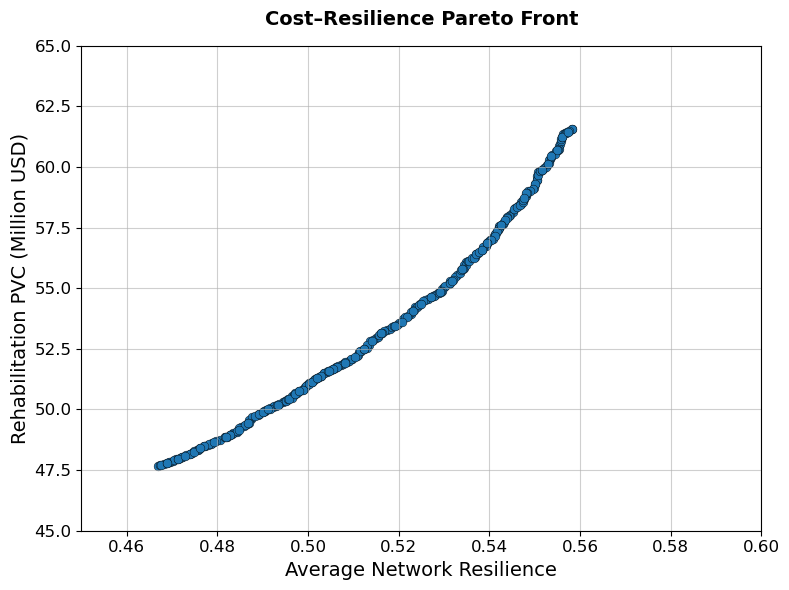

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    -res.F[:,1],
    res.F[:,0],
    s=40,
    edgecolors='black',
    linewidths=0.3
)

plt.xlabel("Average Network Resilience", fontsize=14)
plt.ylabel("Rehabilitation PVC (Million USD)", fontsize=14)

plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.title(
    "Cost–Resilience Pareto Front",
    fontsize=14,
    fontweight='bold',
    pad=15
)

plt.grid(True, alpha=0.6)

plt.xlim(0.45, 0.6)
plt.ylim(45, 65)

plt.tight_layout()

plt.show()

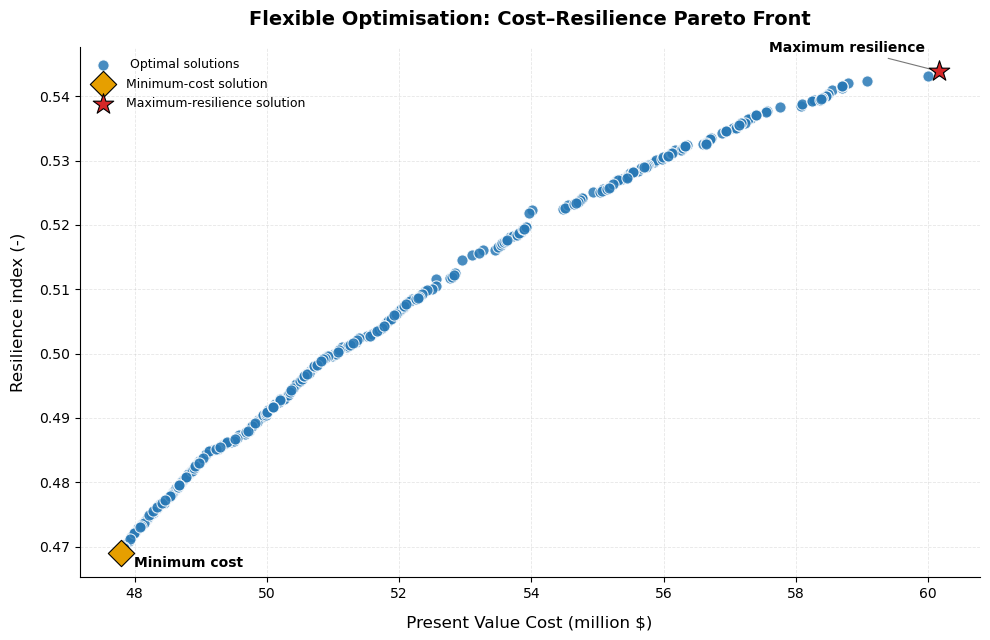

FLEXIBLE OPTIMISATION — KEY PARETO SOLUTIONS

Minimum-cost solution
Pareto index: 1
Cost objective: 47.787690
Resilience: 0.468970

Maximum-resilience solution
Pareto index: 0
Cost objective: 60.166183
Resilience: 0.543873

Total solutions plotted: 300
Figure saved at 300 dpi.


In [8]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# FLEXIBLE OPTIMISATION — COST VS RESILIENCE PARETO FRONT
# ============================================================

# Extract objective values from the NSGA-II results
cost = np.asarray(res.F[:, 0], dtype=float)
resilience = -np.asarray(res.F[:, 1], dtype=float)

# Identify key solutions
min_cost_idx = np.argmin(cost)
max_resilience_idx = np.argmax(resilience)

# Create publication-quality figure
fig, ax = plt.subplots(figsize=(10, 6.5))

# All Pareto solutions
ax.scatter(
    cost,
    resilience,
    s=65,
    color="#2878B5",
    edgecolors="white",
    linewidths=0.8,
    alpha=0.85,
    label=" Optimal solutions",
    zorder=3
)

# Minimum-cost solution
ax.scatter(
    cost[min_cost_idx],
    resilience[min_cost_idx],
    s=180,
    marker="D",
    color="#E69F00",
    edgecolors="black",
    linewidths=0.8,
    label="Minimum-cost solution",
    zorder=5
)

# Maximum-resilience solution
ax.scatter(
    cost[max_resilience_idx],
    resilience[max_resilience_idx],
    s=240,
    marker="*",
    color="#D62728",
    edgecolors="black",
    linewidths=0.8,
    label="Maximum-resilience solution",
    zorder=5
)

# Annotate key solutions
ax.annotate(
    "Minimum cost",
    xy=(cost[min_cost_idx], resilience[min_cost_idx]),
    xytext=(10, -10),
    textcoords="offset points",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8)
)

ax.annotate(
    "Maximum resilience",
    xy=(cost[max_resilience_idx], resilience[max_resilience_idx]),
    xytext=(-10, 14),
    textcoords="offset points",
    ha="right",
    fontsize=10,
    fontweight="bold",
    arrowprops=dict(arrowstyle="-", color="#777777", lw=0.8)
)

# Labels and formatting
ax.set_xlabel(" Present Value Cost (million $) ", fontsize=12, labelpad=10)
ax.set_ylabel("Resilience index (-)", fontsize=12, labelpad=10)

ax.set_title(
    "Flexible Optimisation: Cost–Resilience Pareto Front",
    fontsize=14,
    fontweight="bold",
    pad=16
)

ax.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.3
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=10)
ax.legend(frameon=False, fontsize=9, loc="best")

plt.tight_layout()

plt.savefig(
    "Flexible_Optimization_Cost_Resilience_Pareto.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ============================================================
# PRINT KEY RESULTS
# ============================================================

print("=" * 55)
print("FLEXIBLE OPTIMISATION — KEY PARETO SOLUTIONS")
print("=" * 55)

print("\nMinimum-cost solution")
print(f"Pareto index: {min_cost_idx}")
print(f"Cost objective: {cost[min_cost_idx]:.6f}")
print(f"Resilience: {resilience[min_cost_idx]:.6f}")

print("\nMaximum-resilience solution")
print(f"Pareto index: {max_resilience_idx}")
print(f"Cost objective: {cost[max_resilience_idx]:.6f}")
print(f"Resilience: {resilience[max_resilience_idx]:.6f}")

print("\nTotal solutions plotted:", len(cost))
print("Figure saved at 300 dpi.")


In [37]:
# ============================================================
# FULL VERIFICATION / VALIDATION TESTS
# For NYT Full-Tree Flexible Optimization
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

N_PIPES = 21
N_BLOCKS = 9                 # 3 Year-30 + 6 Year-50 blocks
MAX_OPTION = 15              # option indices: 0 ... 15

# Fixed Year-15 common rehabilitation
YEAR15 = np.array([
    0, 7, 0, 0, 0, 0, 9, 0, 0, 0, 0,
    6, 9, 4, 8, 5, 9, 7, 6, 0, 6
], dtype=int)


# ============================================================
# HELPER FUNCTIONS
# ============================================================

def actual_tree_from_x(x):
    """
    Convert the 9 future increment blocks into actual
    rehabilitation option vectors.

    Block structure:
        0 = Year30 Pathway 1
        1 = Year30 Pathway 2
        2 = Year30 Pathway 3
        3 = Year50 Pathway 1A
        4 = Year50 Pathway 1B
        5 = Year50 Pathway 2A
        6 = Year50 Pathway 2B
        7 = Year50 Pathway 3A
        8 = Year50 Pathway 3B
    """

    x = np.asarray(x).astype(int)

    increments = x.reshape(N_BLOCKS, N_PIPES)

    actual = []

    # --------------------------------------------------------
    # Year 30
    # --------------------------------------------------------

    y30_p1 = np.clip(
        YEAR15 + increments[0],
        0,
        MAX_OPTION
    )

    y30_p2 = np.clip(
        YEAR15 + increments[1],
        0,
        MAX_OPTION
    )

    y30_p3 = np.clip(
        YEAR15 + increments[2],
        0,
        MAX_OPTION
    )

    # --------------------------------------------------------
    # Year 50
    # --------------------------------------------------------

    y50_p1a = np.clip(
        y30_p1 + increments[3],
        0,
        MAX_OPTION
    )

    y50_p1b = np.clip(
        y30_p1 + increments[4],
        0,
        MAX_OPTION
    )

    y50_p2a = np.clip(
        y30_p2 + increments[5],
        0,
        MAX_OPTION
    )

    y50_p2b = np.clip(
        y30_p2 + increments[6],
        0,
        MAX_OPTION
    )

    y50_p3a = np.clip(
        y30_p3 + increments[7],
        0,
        MAX_OPTION
    )

    y50_p3b = np.clip(
        y30_p3 + increments[8],
        0,
        MAX_OPTION
    )

    actual = [
        y30_p1,
        y30_p2,
        y30_p3,
        y50_p1a,
        y50_p1b,
        y50_p2a,
        y50_p2b,
        y50_p3a,
        y50_p3b
    ]

    return actual


def check_monotonicity(x):
    """
    Check that rehabilitation never decreases.
    """

    actual = actual_tree_from_x(x)

    y30_p1 = actual[0]
    y30_p2 = actual[1]
    y30_p3 = actual[2]

    y50_p1a = actual[3]
    y50_p1b = actual[4]
    y50_p2a = actual[5]
    y50_p2b = actual[6]
    y50_p3a = actual[7]
    y50_p3b = actual[8]

    checks = {
        "Year15 -> Year30 P1":
            np.all(y30_p1 >= YEAR15),

        "Year15 -> Year30 P2":
            np.all(y30_p2 >= YEAR15),

        "Year15 -> Year30 P3":
            np.all(y30_p3 >= YEAR15),

        "Year30 P1 -> Year50 P1A":
            np.all(y50_p1a >= y30_p1),

        "Year30 P1 -> Year50 P1B":
            np.all(y50_p1b >= y30_p1),

        "Year30 P2 -> Year50 P2A":
            np.all(y50_p2a >= y30_p2),

        "Year30 P2 -> Year50 P2B":
            np.all(y50_p2b >= y30_p2),

        "Year30 P3 -> Year50 P3A":
            np.all(y50_p3a >= y30_p3),

        "Year30 P3 -> Year50 P3B":
            np.all(y50_p3b >= y30_p3),
    }

    return checks


# ============================================================
# TEST 1 — PARETO SOLUTIONS EXIST
# ============================================================

print("\n" + "=" * 70)
print("TEST 1 — PARETO FRONT")
print("=" * 70)

if res.X is None or len(res.X) == 0:
    print("❌ FAIL: No Pareto solutions found.")
    TEST1 = False
else:
    print(f"Number of Pareto solutions: {len(res.X)}")
    print("✓ PASS: Pareto solutions exist.")
    TEST1 = True


# ============================================================
# TEST 2 — OBJECTIVE VALUES ARE FINITE
# ============================================================

print("\n" + "=" * 70)
print("TEST 2 — OBJECTIVE VALUES")
print("=" * 70)

F = np.asarray(res.F)

finite_objectives = np.all(np.isfinite(F))

if finite_objectives:
    print("✓ PASS: All objective values are finite.")
    print(f"Cost range:       {F[:,0].min():.6f} – {F[:,0].max():.6f} M")
    print(
        f"Resilience range: {-F[:,1].max():.6f} – {-F[:,1].min():.6f}"
    )
    TEST2 = True
else:
    print("❌ FAIL: NaN or infinite objective values detected.")
    TEST2 = False


# ============================================================
# TEST 3 — FEASIBILITY
# ============================================================

print("\n" + "=" * 70)
print("TEST 3 — HYDRAULIC / CONSTRAINT FEASIBILITY")
print("=" * 70)

# res.G contains constraint values.
# For pymoo, G <= 0 means feasible.

if res.G is None:
    print("⚠️ WARNING: res.G is not available.")
    TEST3 = False

else:

    G = np.asarray(res.G)

    if G.size == 0:

        print("⚠️ WARNING: No constraints were returned.")
        TEST3 = False

    else:

        max_violation = np.max(G)
        n_infeasible = np.sum(np.any(G > 1e-6, axis=1))

        print(f"Maximum constraint value: {max_violation:.12e}")
        print(f"Infeasible Pareto solutions: {n_infeasible}")

        if n_infeasible == 0:
            print("✓ PASS: All Pareto solutions are feasible.")
            TEST3 = True
        else:
            print("❌ FAIL: Infeasible Pareto solutions detected.")
            TEST3 = False


# ============================================================
# TEST 4 — MONOTONIC REHABILITATION
# ============================================================

print("\n" + "=" * 70)
print("TEST 4 — MONOTONIC REHABILITATION")
print("=" * 70)

all_monotonic = True

for i, x in enumerate(res.X):

    checks = check_monotonicity(x)

    if not all(checks.values()):

        all_monotonic = False

        print(f"\n❌ Solution {i} failed:")

        for name, passed in checks.items():
            if not passed:
                print("   FAILED:", name)

if all_monotonic:
    print("✓ PASS: Every Pareto solution is monotonic.")
    TEST4 = True
else:
    print("❌ FAIL: At least one solution violates monotonicity.")
    TEST4 = False


# ============================================================
# TEST 5 — SCENARIO PROBABILITIES
# ============================================================

print("\n" + "=" * 70)
print("TEST 5 — SCENARIO PROBABILITIES")
print("=" * 70)

p_year30 = np.array([1/3, 1/3, 1/3])

p_year50 = np.array([
    1/6, 1/6,
    1/6, 1/6,
    1/6, 1/6
])

print("Year-30 probabilities:", p_year30)
print("Sum:", p_year30.sum())

print("\nYear-50 probabilities:", p_year50)
print("Sum:", p_year50.sum())

TEST5 = (
    np.isclose(p_year30.sum(), 1.0)
    and
    np.isclose(p_year50.sum(), 1.0)
)

if TEST5:
    print("✓ PASS: Scenario probabilities sum to 1.")
else:
    print("❌ FAIL: Scenario probabilities do not sum to 1.")


# ============================================================
# TEST 6 — PARETO DOMINANCE CHECK
# ============================================================

print("\n" + "=" * 70)
print("TEST 6 — PARETO DOMINANCE")
print("=" * 70)

# Objectives:
#   F[:,0] = minimize cost
#   F[:,1] = minimize negative resilience
#
# A solution dominates another if it is <= in all objectives
# and strictly better in at least one.

dominance_error = False

for i in range(len(F)):

    for j in range(len(F)):

        if i == j:
            continue

        i_dominates_j = (
            np.all(F[i] <= F[j] + 1e-10)
            and
            np.any(F[i] < F[j] - 1e-10)
        )

        if i_dominates_j:
            dominance_error = True
            print(
                f"❌ Solution {i} dominates solution {j}"
            )
            break

    if dominance_error:
        break


if not dominance_error:
    print("✓ PASS: No Pareto solution is dominated by another.")
    TEST6 = True
else:
    print("❌ FAIL: Dominated solutions found.")
    TEST6 = False


# ============================================================
# TEST 7 — ZERO-ADAPTATION SANITY TEST
# ============================================================

print("\n" + "=" * 70)
print("TEST 7 — ZERO FUTURE ADAPTATION")
print("=" * 70)

# All future increments = zero.
# Therefore:
#
# Year30 = Year15
# Year50 = Year30
#
# This is a structural sanity test.
# It does NOT have to be hydraulically feasible because the
# future demand scenarios may require additional rehabilitation.

zero_x = np.zeros(N_BLOCKS * N_PIPES, dtype=int)

zero_actual = actual_tree_from_x(zero_x)

zero_structure_ok = True

for block in zero_actual:

    if not np.array_equal(block, YEAR15):
        zero_structure_ok = False

if zero_structure_ok:

    print("✓ PASS: Zero increments preserve the Year-15 network.")
    print("  Year30 = Year15")
    print("  Year50 = Year15")

    # Evaluate it through the actual optimization problem
    try:

        F_zero, G_zero = problem.evaluate(
            zero_x.reshape(1, -1),
            return_values_of=["F", "G"]
        )

        print("\nZero-adaptation objective:")
        print(f"  Cost:       {F_zero[0,0]:.6f} M")
        print(f"  Resilience: {-F_zero[0,1]:.6f}")

        max_zero_violation = np.max(G_zero)

        print(
            f"  Maximum constraint value: "
            f"{max_zero_violation:.6e}"
        )

        if max_zero_violation <= 1e-6:
            print("  Hydraulic result: FEASIBLE")
        else:
            print(
                "  Hydraulic result: INFEASIBLE "
                "(this is not automatically an error)"
            )

        TEST7 = True

    except Exception as e:

        print("⚠️ Could not evaluate zero-adaptation case.")
        print("Error:", e)
        TEST7 = False

else:

    print("❌ FAIL: Zero-increment tree changed the network.")
    TEST7 = False


# ============================================================
# TEST 8 — MAXIMUM-REHABILITATION SANITY TEST
# ============================================================

print("\n" + "=" * 70)
print("TEST 8 — MAXIMUM REHABILITATION SANITY TEST")
print("=" * 70)

# Every future increment is set to the maximum.
# Because the model clips at MAX_OPTION, all future stages
# should eventually become option 15.

max_x = np.full(
    N_BLOCKS * N_PIPES,
    MAX_OPTION,
    dtype=int
)

max_actual = actual_tree_from_x(max_x)

max_structure_ok = all(
    np.all(block == MAX_OPTION)
    for block in max_actual
)

if max_structure_ok:

    print(
        f"✓ PASS: Maximum increments lead to "
        f"maximum option ({MAX_OPTION}) everywhere."
    )

    try:

        F_max, G_max = problem.evaluate(
            max_x.reshape(1, -1),
            return_values_of=["F", "G"]
        )

        print("\nMaximum-rehabilitation objective:")
        print(f"  Cost:       {F_max[0,0]:.6f} M")
        print(f"  Resilience: {-F_max[0,1]:.6f}")

        max_violation = np.max(G_max)

        print(
            f"  Maximum constraint value: "
            f"{max_violation:.6e}"
        )

        if max_violation <= 1e-6:
            print("  Hydraulic result: FEASIBLE")
        else:
            print("  Hydraulic result: INFEASIBLE")

        TEST8 = True

    except Exception as e:

        print("⚠️ Could not evaluate maximum-rehabilitation case.")
        print("Error:", e)
        TEST8 = False

else:

    print("❌ FAIL: Maximum increments did not reach maximum option.")
    TEST8 = False


# ============================================================
# TEST 9 — PARETO FRONT RANGE / SANITY
# ============================================================

print("\n" + "=" * 70)
print("TEST 9 — PARETO FRONT SANITY")
print("=" * 70)

costs = F[:, 0]
resiliencies = -F[:, 1]

print(f"Number of solutions: {len(F)}")
print(f"Minimum cost:       {costs.min():.6f} M")
print(f"Maximum cost:       {costs.max():.6f} M")
print(f"Minimum resilience: {resiliencies.min():.6f}")
print(f"Maximum resilience: {resiliencies.max():.6f}")

# Basic sanity:
# More than one distinct objective point should exist.

n_unique = len(
    np.unique(
        np.round(
            np.column_stack([costs, resiliencies]),
            decimals=8
        ),
        axis=0
    )
)

print(f"Unique objective points: {n_unique}")

if n_unique > 1:
    print("✓ PASS: Multiple distinct Pareto objective points exist.")
    TEST9 = True
else:
    print("❌ FAIL: Pareto front contains only one objective point.")
    TEST9 = False


# ============================================================
# TEST 10 — MONOTONICITY DETAILS FOR ALL PARETO SOLUTIONS
# ============================================================

print("\n" + "=" * 70)
print("TEST 10 — DETAILED MONOTONICITY CHECK")
print("=" * 70)

monotonicity_table = []

for i, x in enumerate(res.X):

    checks = check_monotonicity(x)

    monotonicity_table.append({
        "Solution": i,
        "Y15→Y30 P1": checks["Year15 -> Year30 P1"],
        "Y15→Y30 P2": checks["Year15 -> Year30 P2"],
        "Y15→Y30 P3": checks["Year15 -> Year30 P3"],
        "Y30P1→Y50A": checks["Year30 P1 -> Year50 P1A"],
        "Y30P1→Y50B": checks["Year30 P1 -> Year50 P1B"],
        "Y30P2→Y50A": checks["Year30 P2 -> Year50 P2A"],
        "Y30P2→Y50B": checks["Year30 P2 -> Year50 P2B"],
        "Y30P3→Y50A": checks["Year30 P3 -> Year50 P3A"],
        "Y30P3→Y50B": checks["Year30 P3 -> Year50 P3B"],
    })

monotonicity_df = pd.DataFrame(monotonicity_table)

print(monotonicity_df)


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("FINAL VERIFICATION SUMMARY")
print("=" * 70)

tests = {
    "Pareto solutions exist": TEST1,
    "Finite objective values": TEST2,
    "Hydraulic/constraint feasibility": TEST3,
    "Monotonic rehabilitation": TEST4,
    "Scenario probabilities": TEST5,
    "Pareto dominance": TEST6,
    "Zero-adaptation structure": TEST7,
    "Maximum-rehabilitation structure": TEST8,
    "Pareto front sanity": TEST9,
}

for name, result in tests.items():

    status = "PASS ✓" if result else "FAIL ❌"

    print(f"{status:8s} | {name}")


all_pass = all(tests.values())

print("\n" + "=" * 70)

if all_pass:

    print("OVERALL RESULT: ALL AUTOMATED TESTS PASSED ✓")

else:

    print(
        "OVERALL RESULT: SOME TESTS REQUIRE ATTENTION ❌"
    )

print("=" * 70)


TEST 1 — PARETO FRONT
Number of Pareto solutions: 300
✓ PASS: Pareto solutions exist.

TEST 2 — OBJECTIVE VALUES
✓ PASS: All objective values are finite.
Cost range:       47.649118 – 61.565070 M
Resilience range: 0.466798 – 0.558234

TEST 3 — HYDRAULIC / CONSTRAINT FEASIBILITY
Maximum constraint value: -1.718597656249e-02
Infeasible Pareto solutions: 0
✓ PASS: All Pareto solutions are feasible.

TEST 4 — MONOTONIC REHABILITATION
✓ PASS: Every Pareto solution is monotonic.

TEST 5 — SCENARIO PROBABILITIES
Year-30 probabilities: [0.333 0.333 0.333]
Sum: 1.0

Year-50 probabilities: [0.167 0.167 0.167 0.167 0.167 0.167]
Sum: 0.9999999999999999
✓ PASS: Scenario probabilities sum to 1.

TEST 6 — PARETO DOMINANCE
✓ PASS: No Pareto solution is dominated by another.

TEST 7 — ZERO FUTURE ADAPTATION
✓ PASS: Zero increments preserve the Year-15 network.
  Year30 = Year15
  Year50 = Year15

Zero-adaptation objective:
  Cost:       45.169541 M
  Resilience: 0.447940
  Maximum constraint value: 8.

In [26]:
# ============================================================
# INDEPENDENT COST + RESILIENCE VERIFICATION
# ============================================================
#
# This verification does NOT use:
#   problem.calculate_stage_cost()
#   problem.calculate_resilience()
#
# Instead, it independently:
#
#   1. Extracts one complete Pareto tree
#   2. Converts increments -> actual rehabilitation options
#   3. Recalculates intervention costs from pipe lengths
#   4. Applies discounting
#   5. Applies scenario probabilities
#   6. Rebuilds each hydraulic state from the ORIGINAL network
#   7. Runs EPANET independently
#   8. Recalculates the resilience formula independently
#   9. Compares everything with res.F
#
# ============================================================


import numpy as np
import pandas as pd
import wntr


# ============================================================
# SETTINGS
# ============================================================

DISCOUNT_RATE = 0.04

# Planning years relative to the original/base network
YEAR15 = 15
YEAR30 = 30
YEAR50 = 50

# Demand factors
DEMAND_Y15 = 1.00

DEMAND_Y30 = {
    "P1": 0.95,
    "P2": 1.05,
    "P3": 1.07
}

DEMAND_Y50 = {
    "P1A": 0.855,
    "P1B": 1.0165,

    "P2A": 1.155,
    "P2B": 1.176,

    "P3A": 1.1235,
    "P3B": 1.1021
}

# Scenario probabilities
P_Y30 = {
    "P1": 1/3,
    "P2": 1/3,
    "P3": 1/3
}

P_Y50 = {
    "P1A": 1/6,
    "P1B": 1/6,
    "P2A": 1/6,
    "P2B": 1/6,
    "P3A": 1/6,
    "P3B": 1/6
}

# Rehabilitation diameter options
DIAMETERS_IN = np.array([
    0,
    36,
    48,
    60,
    72,
    84,
    96,
    108,
    120,
    132,
    144,
    156,
    168,
    180,
    192,
    204
])

# Fixed Year-15 common decision
YEAR15_VECTOR = np.array([
    0, 7, 0, 0, 0, 0, 9, 0, 0, 0, 0,
    6, 9, 4, 8, 5, 9, 7, 6, 0, 6
], dtype=int)


# ============================================================
# REQUIRED HEADS
# ============================================================

REQUIRED_HEAD_FT = {

    "2": 255.0,
    "3": 255.0,
    "4": 255.0,
    "5": 255.0,
    "6": 255.0,
    "7": 255.0,
    "8": 255.0,
    "9": 255.0,
    "10": 255.0,
    "11": 255.0,
    "12": 255.0,
    "13": 255.0,
    "14": 255.0,
    "15": 255.0,
    "16": 260.0,
    "17": 272.8,
    "18": 255.0,
    "19": 255.0,
    "20": 255.0
}

REQUIRED_HEAD_M = {
    node: value * 0.3048
    for node, value in REQUIRED_HEAD_FT.items()
}


# ============================================================
# GET ORIGINAL NETWORK
# ============================================================

original_wn = wntr.network.WaterNetworkModel(
    problem.inp_file
)

pipe_names = list(
    original_wn.pipe_name_list
)

print("=" * 70)
print("INDEPENDENT VERIFICATION SETUP")
print("=" * 70)

print("Number of candidate pipes:", len(pipe_names))
print("Number of diameter options:", len(DIAMETERS_IN))
print("Discount rate:", DISCOUNT_RATE)


# ============================================================
# HELPER 1 — CONVERT INCREMENTS TO ACTUAL TREE
# ============================================================

def independent_actual_tree(x):

    increments = np.asarray(x).astype(int).reshape(9, 21)

    # Year 30
    y30_p1 = np.clip(
        YEAR15_VECTOR + increments[0],
        0,
        len(DIAMETERS_IN) - 1
    )

    y30_p2 = np.clip(
        YEAR15_VECTOR + increments[1],
        0,
        len(DIAMETERS_IN) - 1
    )

    y30_p3 = np.clip(
        YEAR15_VECTOR + increments[2],
        0,
        len(DIAMETERS_IN) - 1
    )

    # Year 50
    y50_p1a = np.clip(
        y30_p1 + increments[3],
        0,
        len(DIAMETERS_IN) - 1
    )

    y50_p1b = np.clip(
        y30_p1 + increments[4],
        0,
        len(DIAMETERS_IN) - 1
    )

    y50_p2a = np.clip(
        y30_p2 + increments[5],
        0,
        len(DIAMETERS_IN) - 1
    )

    y50_p2b = np.clip(
        y30_p2 + increments[6],
        0,
        len(DIAMETERS_IN) - 1
    )

    y50_p3a = np.clip(
        y30_p3 + increments[7],
        0,
        len(DIAMETERS_IN) - 1
    )

    y50_p3b = np.clip(
        y30_p3 + increments[8],
        0,
        len(DIAMETERS_IN) - 1
    )

    return {

        "Y15": YEAR15_VECTOR.copy(),

        "Y30_P1": y30_p1,
        "Y30_P2": y30_p2,
        "Y30_P3": y30_p3,

        "Y50_P1A": y50_p1a,
        "Y50_P1B": y50_p1b,

        "Y50_P2A": y50_p2a,
        "Y50_P2B": y50_p2b,

        "Y50_P3A": y50_p3a,
        "Y50_P3B": y50_p3b
    }


# ============================================================
# HELPER 2 — INDEPENDENT STAGE COST
# ============================================================

def independent_stage_cost(
    current_x,
    previous_x,
    wn_original
):

    cost = 0.0

    for i, pipe_name in enumerate(pipe_names):

        current_option = int(
            np.clip(
                round(current_x[i]),
                0,
                len(DIAMETERS_IN) - 1
            )
        )

        previous_option = int(
            np.clip(
                round(previous_x[i]),
                0,
                len(DIAMETERS_IN) - 1
            )
        )

        # Only pay when rehabilitation increases
        if current_option > previous_option:

            diameter_in = DIAMETERS_IN[current_option]

            original_pipe = wn_original.get_link(
                pipe_name
            )

            length_ft = (
                original_pipe.length / 0.3048
            )

            intervention_cost = (
                1.1
                *
                (diameter_in ** 1.24)
                *
                length_ft
            )

            cost += intervention_cost / 1e6

    return cost


# ============================================================
# HELPER 3 — ADD REHABILITATION TO A FRESH NETWORK
# ============================================================

def independent_apply_rehabilitation(
    wn,
    stage_x
):

    for i, pipe_name in enumerate(pipe_names):

        option = int(
            np.clip(
                round(stage_x[i]),
                0,
                len(DIAMETERS_IN) - 1
            )
        )

        # No rehabilitation
        if option == 0:
            continue

        diameter_in = DIAMETERS_IN[option]

        original_pipe = wn.get_link(
            pipe_name
        )

        parallel_name = (
            f"{pipe_name}_parallel"
        )

        # Add the rehabilitation pipe
        wn.add_pipe(

            parallel_name,

            original_pipe.start_node_name,

            original_pipe.end_node_name,

            length=original_pipe.length,

            diameter=(
                diameter_in * 0.0254
            ),

            roughness=original_pipe.roughness
        )


# ============================================================
# HELPER 4 — APPLY DEMAND FACTOR
# ============================================================

def independent_apply_demand(
    wn,
    factor
):

    for node_name in wn.junction_name_list:

        node = wn.get_node(node_name)

        for demand in node.demand_timeseries_list:

            demand.base_value *= factor


# ============================================================
# HELPER 5 — RUN HYDRAULICS
# ============================================================

def independent_run_network(
    stage_x,
    demand_factor
):

    # Start from completely original network
    wn = wntr.network.WaterNetworkModel(
        problem.inp_file
    )

    # Apply demand
    independent_apply_demand(
        wn,
        demand_factor
    )

    # Apply rehabilitation
    independent_apply_rehabilitation(
        wn,
        stage_x
    )

    # Run EPANET
    sim = wntr.sim.EpanetSimulator(wn)

    results = sim.run_sim()

    return wn, results


# ============================================================
# HELPER 6 — INDEPENDENT RESILIENCE
# ============================================================

def independent_resilience(
    wn,
    results
):

    # First hydraulic timestep
    heads = (
        results.node["head"].iloc[0]
    )

    demands = (
        results.node["demand"].iloc[0]
    )

    # --------------------------------------------------------
    # Calculate Ui
    # --------------------------------------------------------

    Ui = {}

    for node_name in REQUIRED_HEAD_M.keys():

        connected_diameters = []

        for link_name in wn.pipe_name_list:

            pipe = wn.get_link(
                link_name
            )

            if (
                pipe.start_node_name == node_name
                or
                pipe.end_node_name == node_name
            ):

                connected_diameters.append(
                    pipe.diameter / 0.0254
                )

        if len(connected_diameters) > 0:

            sum_diameter = np.sum(
                connected_diameters
            )

            max_diameter = np.max(
                connected_diameters
            )

            n_pipe = len(
                connected_diameters
            )

            Ui[node_name] = (
                sum_diameter
                /
                (
                    n_pipe
                    *
                    max_diameter
                )
            )

        else:

            Ui[node_name] = 0.0


    # --------------------------------------------------------
    # Calculate X and Xmax
    # --------------------------------------------------------

    X = 0.0
    Xmax = 0.0

    for node_name in REQUIRED_HEAD_M.keys():

        X += (
            Ui[node_name]
            *
            demands[node_name]
            *
            (
                heads[node_name]
                -
                REQUIRED_HEAD_M[node_name]
            )
        )

        Xmax -= (
            demands[node_name]
            *
            REQUIRED_HEAD_M[node_name]
        )


    # --------------------------------------------------------
    # Reservoir contribution
    # --------------------------------------------------------

    reservoir_name = (
        wn.reservoir_name_list[0]
    )

    reservoir_head = (
        heads[reservoir_name]
    )

    reservoir_discharge = (
        demands[reservoir_name]
    )

    Xmax += (
        -reservoir_discharge
        *
        reservoir_head
    )


    # --------------------------------------------------------
    # Final resilience
    # --------------------------------------------------------

    return X / Xmax


# ============================================================
# HELPER 7 — VERIFY ONE COMPLETE TREE
# ============================================================

def verify_tree(
    x,
    solution_number
):

    print("\n")
    print("=" * 70)
    print(
        f"VERIFYING PARETO SOLUTION #{solution_number}"
    )
    print("=" * 70)

    tree = independent_actual_tree(x)


    # ========================================================
    # A. INDEPENDENT COST CALCULATION
    # ========================================================

    y15 = tree["Y15"]

    y30_p1 = tree["Y30_P1"]
    y30_p2 = tree["Y30_P2"]
    y30_p3 = tree["Y30_P3"]

    y50_p1a = tree["Y50_P1A"]
    y50_p1b = tree["Y50_P1B"]

    y50_p2a = tree["Y50_P2A"]
    y50_p2b = tree["Y50_P2B"]

    y50_p3a = tree["Y50_P3A"]
    y50_p3b = tree["Y50_P3B"]


    # --------------------------------------------------------
    # Year 15
    # --------------------------------------------------------

    zero_vector = np.zeros(
        len(pipe_names),
        dtype=int
    )

    cost_y15 = independent_stage_cost(
        y15,
        zero_vector,
        original_wn
    )


    # --------------------------------------------------------
    # Year 30
    # --------------------------------------------------------

    cost_y30_p1 = independent_stage_cost(
        y30_p1,
        y15,
        original_wn
    )

    cost_y30_p2 = independent_stage_cost(
        y30_p2,
        y15,
        original_wn
    )

    cost_y30_p3 = independent_stage_cost(
        y30_p3,
        y15,
        original_wn
    )


    # --------------------------------------------------------
    # Year 50
    # --------------------------------------------------------

    cost_y50_p1a = independent_stage_cost(
        y50_p1a,
        y30_p1,
        original_wn
    )

    cost_y50_p1b = independent_stage_cost(
        y50_p1b,
        y30_p1,
        original_wn
    )

    cost_y50_p2a = independent_stage_cost(
        y50_p2a,
        y30_p2,
        original_wn
    )

    cost_y50_p2b = independent_stage_cost(
        y50_p2b,
        y30_p2,
        original_wn
    )

    cost_y50_p3a = independent_stage_cost(
        y50_p3a,
        y30_p3,
        original_wn
    )

    cost_y50_p3b = independent_stage_cost(
        y50_p3b,
        y30_p3,
        original_wn
    )


    # ========================================================
    # DISCOUNT EACH COST
    # ========================================================

    pv_y15 = (
        cost_y15
        /
        (1 + DISCOUNT_RATE) ** YEAR15
    )

    pv_y30_p1 = (
        cost_y30_p1
        /
        (1 + DISCOUNT_RATE) ** YEAR30
    )

    pv_y30_p2 = (
        cost_y30_p2
        /
        (1 + DISCOUNT_RATE) ** YEAR30
    )

    pv_y30_p3 = (
        cost_y30_p3
        /
        (1 + DISCOUNT_RATE) ** YEAR30
    )

    pv_y50_p1a = (
        cost_y50_p1a
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )

    pv_y50_p1b = (
        cost_y50_p1b
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )

    pv_y50_p2a = (
        cost_y50_p2a
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )

    pv_y50_p2b = (
        cost_y50_p2b
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )

    pv_y50_p3a = (
        cost_y50_p3a
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )

    pv_y50_p3b = (
        cost_y50_p3b
        /
        (1 + DISCOUNT_RATE) ** YEAR50
    )


    # ========================================================
    # EXPECTED DISCOUNTED COST
    # ========================================================

    expected_pv_y30 = (
        P_Y30["P1"] * pv_y30_p1
        +
        P_Y30["P2"] * pv_y30_p2
        +
        P_Y30["P3"] * pv_y30_p3
    )

    expected_pv_y50 = (
        P_Y50["P1A"] * pv_y50_p1a
        +
        P_Y50["P1B"] * pv_y50_p1b
        +
        P_Y50["P2A"] * pv_y50_p2a
        +
        P_Y50["P2B"] * pv_y50_p2b
        +
        P_Y50["P3A"] * pv_y50_p3a
        +
        P_Y50["P3B"] * pv_y50_p3b
    )

    independent_pv_cost = (
        pv_y15
        +
        expected_pv_y30
        +
        expected_pv_y50
    )


    # ========================================================
    # PRINT COST BREAKDOWN
    # ========================================================

    print("\nINDEPENDENT COST CALCULATION")
    print("-" * 70)

    print(
        f"Year 15 cost:       {cost_y15:.9f} M"
    )

    print(
        f"Year 30 P1 cost:    {cost_y30_p1:.9f} M"
    )

    print(
        f"Year 30 P2 cost:    {cost_y30_p2:.9f} M"
    )

    print(
        f"Year 30 P3 cost:    {cost_y30_p3:.9f} M"
    )

    print(
        f"Year 50 P1A cost:   {cost_y50_p1a:.9f} M"
    )

    print(
        f"Year 50 P1B cost:   {cost_y50_p1b:.9f} M"
    )

    print(
        f"Year 50 P2A cost:   {cost_y50_p2a:.9f} M"
    )

    print(
        f"Year 50 P2B cost:   {cost_y50_p2b:.9f} M"
    )

    print(
        f"Year 50 P3A cost:   {cost_y50_p3a:.9f} M"
    )

    print(
        f"Year 50 P3B cost:   {cost_y50_p3b:.9f} M"
    )

    print("\nDiscounted expected components:")

    print(
        f"PV Year 15:         {pv_y15:.9f} M"
    )

    print(
        f"Expected PV Year30: {expected_pv_y30:.9f} M"
    )

    print(
        f"Expected PV Year50: {expected_pv_y50:.9f} M"
    )

    print(
        f"\nINDEPENDENT PV COST: "
        f"{independent_pv_cost:.9f} M"
    )


    # ========================================================
    # B. INDEPENDENT HYDRAULIC / RESILIENCE CALCULATION
    # ========================================================

    states = {

        "Y15": (
            y15,
            DEMAND_Y15
        ),

        "Y30_P1": (
            y30_p1,
            DEMAND_Y30["P1"]
        ),

        "Y30_P2": (
            y30_p2,
            DEMAND_Y30["P2"]
        ),

        "Y30_P3": (
            y30_p3,
            DEMAND_Y30["P3"]
        ),

        "Y50_P1A": (
            y50_p1a,
            DEMAND_Y50["P1A"]
        ),

        "Y50_P1B": (
            y50_p1b,
            DEMAND_Y50["P1B"]
        ),

        "Y50_P2A": (
            y50_p2a,
            DEMAND_Y50["P2A"]
        ),

        "Y50_P2B": (
            y50_p2b,
            DEMAND_Y50["P2B"]
        ),

        "Y50_P3A": (
            y50_p3a,
            DEMAND_Y50["P3A"]
        ),

        "Y50_P3B": (
            y50_p3b,
            DEMAND_Y50["P3B"]
        )
    }


    resilience_results = {}

    print("\n")
    print("=" * 70)
    print("INDEPENDENT RESILIENCE CALCULATION")
    print("=" * 70)

    for state_name, (
        stage_x,
        demand_factor
    ) in states.items():

        print(
            f"Running {state_name} "
            f"(demand factor = {demand_factor})..."
        )

        wn_state, hydraulic_results = (
            independent_run_network(
                stage_x,
                demand_factor
            )
        )

        R = independent_resilience(
            wn_state,
            hydraulic_results
        )

        resilience_results[state_name] = R

        print(
            f"  Resilience = {R:.9f}"
        )


    # ========================================================
    # EXPECTED RESILIENCE
    # ========================================================

    R15 = resilience_results["Y15"]

    R30_expected = (
        P_Y30["P1"] * resilience_results["Y30_P1"]
        +
        P_Y30["P2"] * resilience_results["Y30_P2"]
        +
        P_Y30["P3"] * resilience_results["Y30_P3"]
    )

    R50_expected = (
        P_Y50["P1A"] * resilience_results["Y50_P1A"]
        +
        P_Y50["P1B"] * resilience_results["Y50_P1B"]
        +
        P_Y50["P2A"] * resilience_results["Y50_P2A"]
        +
        P_Y50["P2B"] * resilience_results["Y50_P2B"]
        +
        P_Y50["P3A"] * resilience_results["Y50_P3A"]
        +
        P_Y50["P3B"] * resilience_results["Y50_P3B"]
    )


    # --------------------------------------------------------
    # IMPORTANT:
    #
    # This is the aggregation that we are testing against.
    #
    # Your current full-tree code uses:
    #
    # average resilience =
    #
    # (Year15 + expected Year30 + expected Year50) / 3
    #
    # --------------------------------------------------------

    independent_average_resilience = (
        R15
        +
        R30_expected
        +
        R50_expected
    ) / 3


    print("\nRESILIENCE SUMMARY")
    print("-" * 70)

    print(
        f"Year 15 resilience:       {R15:.9f}"
    )

    print(
        f"Expected Year 30:         {R30_expected:.9f}"
    )

    print(
        f"Expected Year 50:         {R50_expected:.9f}"
    )

    print(
        f"\nINDEPENDENT AVG RESILIENCE: "
        f"{independent_average_resilience:.9f}"
    )


    # ========================================================
    # C. COMPARE WITH OPTIMIZER
    # ========================================================

    optimizer_cost = res.F[
        solution_number,
        0
    ]

    optimizer_resilience = -res.F[
        solution_number,
        1
    ]


    cost_difference = (
        independent_pv_cost
        -
        optimizer_cost
    )

    resilience_difference = (
        independent_average_resilience
        -
        optimizer_resilience
    )


    print("\n")
    print("=" * 70)
    print("COMPARISON WITH OPTIMIZER")
    print("=" * 70)

    print("\nCOST")
    print("-" * 70)

    print(
        f"Optimizer:    {optimizer_cost:.12f} M"
    )

    print(
        f"Independent:  {independent_pv_cost:.12f} M"
    )

    print(
        f"Difference:   {cost_difference:.12e} M"
    )


    print("\nRESILIENCE")
    print("-" * 70)

    print(
        f"Optimizer:    {optimizer_resilience:.12f}"
    )

    print(
        f"Independent:  {independent_average_resilience:.12f}"
    )

    print(
        f"Difference:   {resilience_difference:.12e}"
    )


    # ========================================================
    # PASS / FAIL
    # ========================================================

    COST_TOL = 1e-6
    RESILIENCE_TOL = 1e-8

    cost_pass = (
        abs(cost_difference)
        <= COST_TOL
    )

    resilience_pass = (
        abs(resilience_difference)
        <= RESILIENCE_TOL
    )


    print("\n")
    print("=" * 70)
    print("VERIFICATION RESULT")
    print("=" * 70)

    if cost_pass:
        print(
            "✓ COST VERIFICATION PASSED"
        )
    else:
        print(
            "❌ COST VERIFICATION FAILED"
        )

    if resilience_pass:
        print(
            "✓ RESILIENCE VERIFICATION PASSED"
        )
    else:
        print(
            "❌ RESILIENCE VERIFICATION FAILED"
        )


    return {

        "optimizer_cost": optimizer_cost,
        "independent_cost": independent_pv_cost,
        "cost_difference": cost_difference,

        "optimizer_resilience": optimizer_resilience,
        "independent_resilience":
            independent_average_resilience,
        "resilience_difference":
            resilience_difference,

        "resilience_by_state":
            resilience_results,

        "cost_by_stage": {

            "Y15": cost_y15,

            "Y30_P1": cost_y30_p1,
            "Y30_P2": cost_y30_p2,
            "Y30_P3": cost_y30_p3,

            "Y50_P1A": cost_y50_p1a,
            "Y50_P1B": cost_y50_p1b,

            "Y50_P2A": cost_y50_p2a,
            "Y50_P2B": cost_y50_p2b,

            "Y50_P3A": cost_y50_p3a,
            "Y50_P3B": cost_y50_p3b
        }
    }


# ============================================================
# RUN VERIFICATION
# ============================================================

# Find the lowest-cost Pareto solution
lowest_cost_index = np.argmin(
    res.F[:, 0]
)

verification_result = verify_tree(
    res.X[lowest_cost_index],
    lowest_cost_index
)

INDEPENDENT VERIFICATION SETUP
Number of candidate pipes: 21
Number of diameter options: 16
Discount rate: 0.04


VERIFYING PARETO SOLUTION #2

INDEPENDENT COST CALCULATION
----------------------------------------------------------------------
Year 15 cost:       81.347790658 M
Year 30 P1 cost:    0.000000000 M
Year 30 P2 cost:    7.108289345 M
Year 30 P3 cost:    3.104252139 M
Year 50 P1A cost:   0.000000000 M
Year 50 P1B cost:   18.204638038 M
Year 50 P2A cost:   34.857658241 M
Year 50 P2B cost:   27.938801384 M
Year 50 P3A cost:   5.437037759 M
Year 50 P3B cost:   9.280461002 M

Discounted expected components:
PV Year 15:         45.169540526 M
Expected PV Year30: 1.049572396 M
Expected PV Year50: 2.244802340 M

INDEPENDENT PV COST: 48.463915262 M


INDEPENDENT RESILIENCE CALCULATION
Running Y15 (demand factor = 1.0)...
  Resilience = 0.469035133
Running Y30_P1 (demand factor = 0.95)...
  Resilience = 0.499013513
Running Y30_P2 (demand factor = 1.05)...
  Resilience = 0.453723608
Ru

SELECTED FLEXIBLE-TREE SOLUTION
Solution index: 2
PV cost: 48.463915 million
Average resilience: 0.467476
Candidate pipes: 21


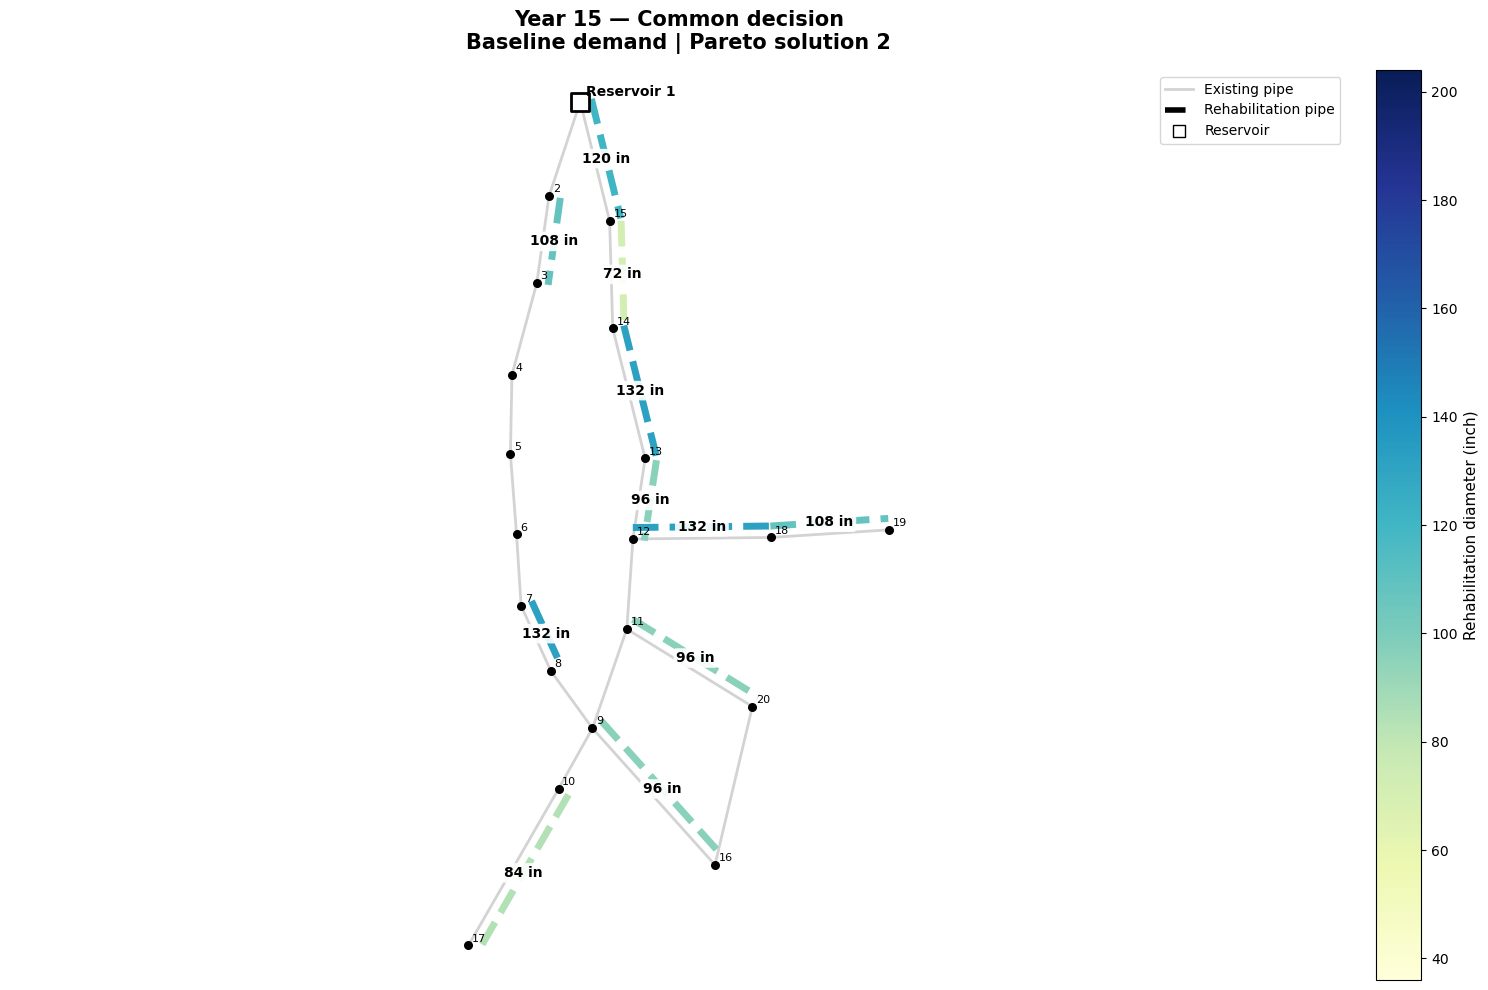

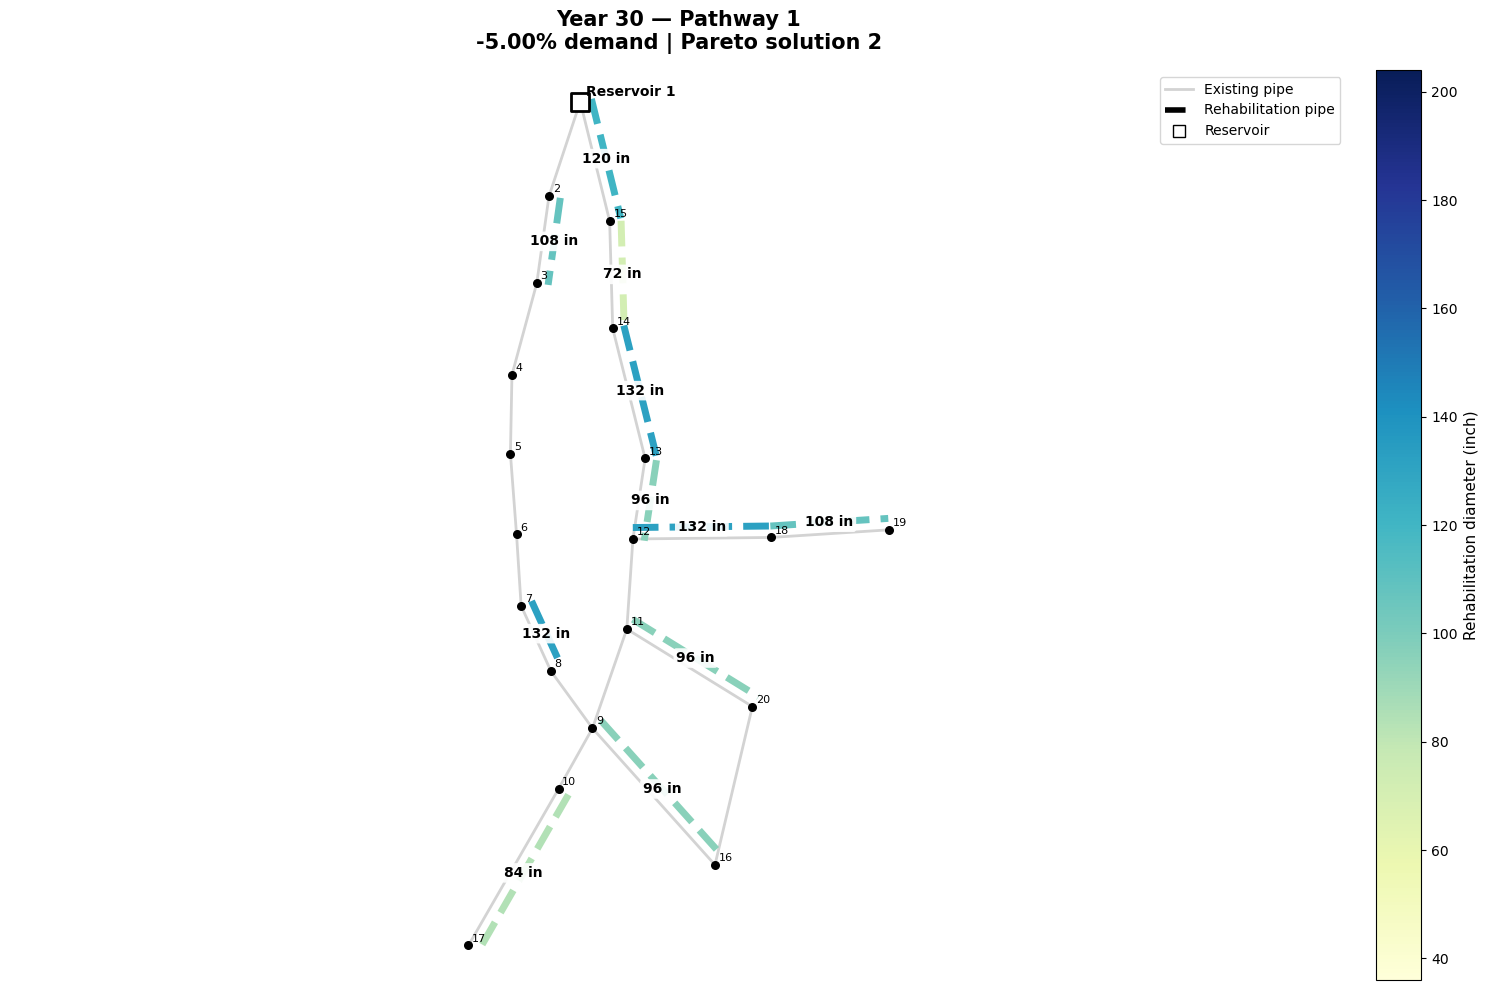

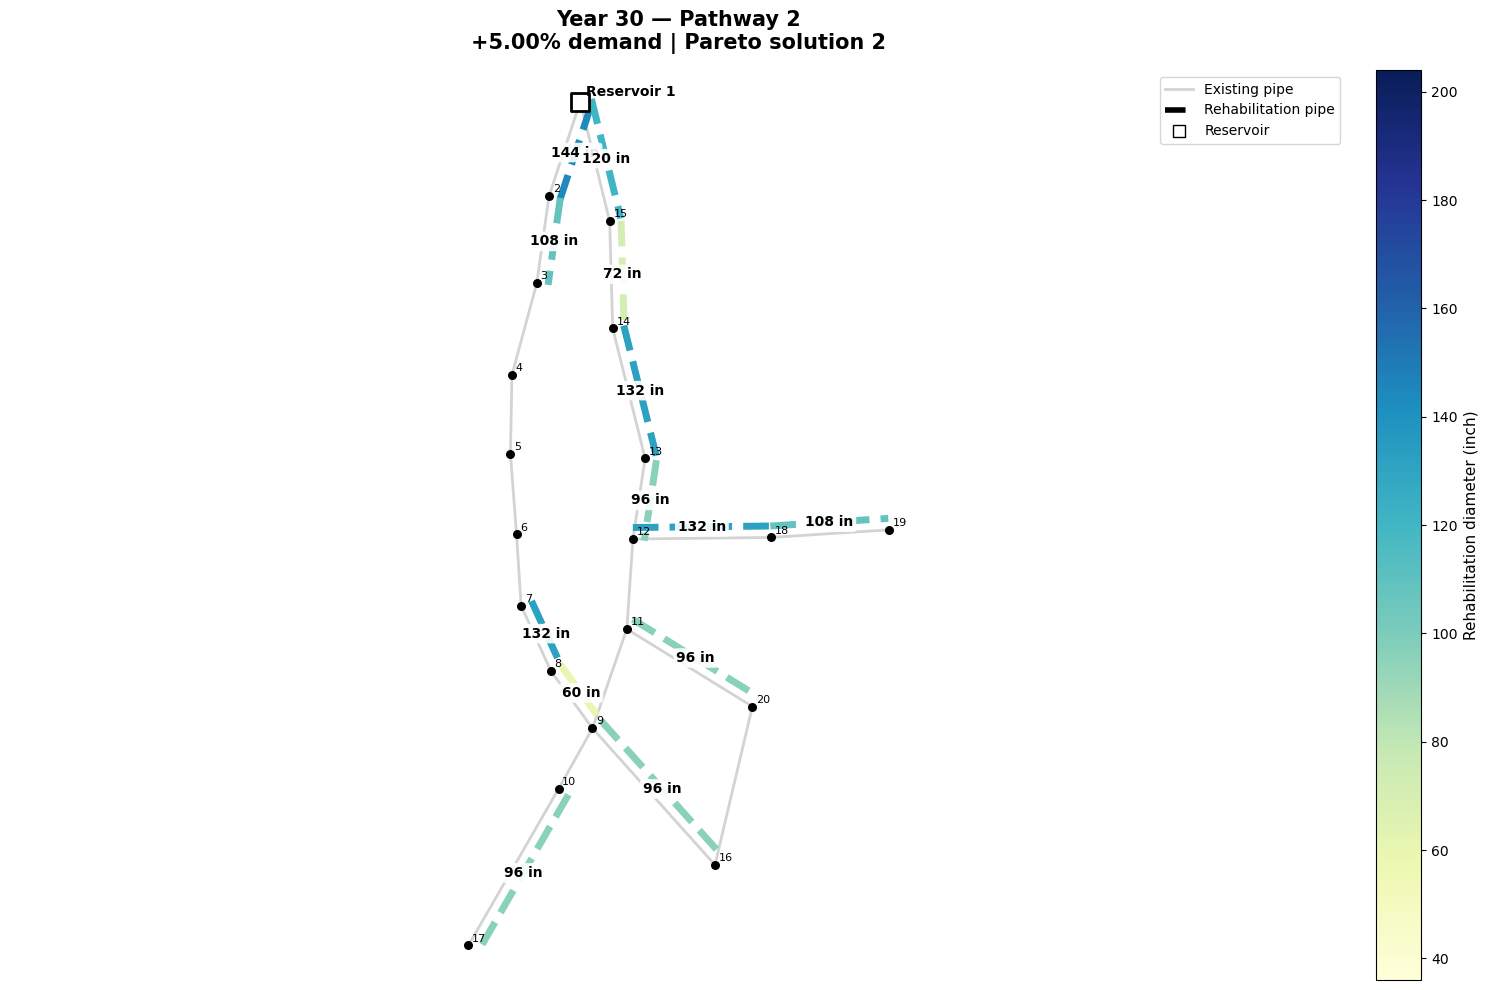

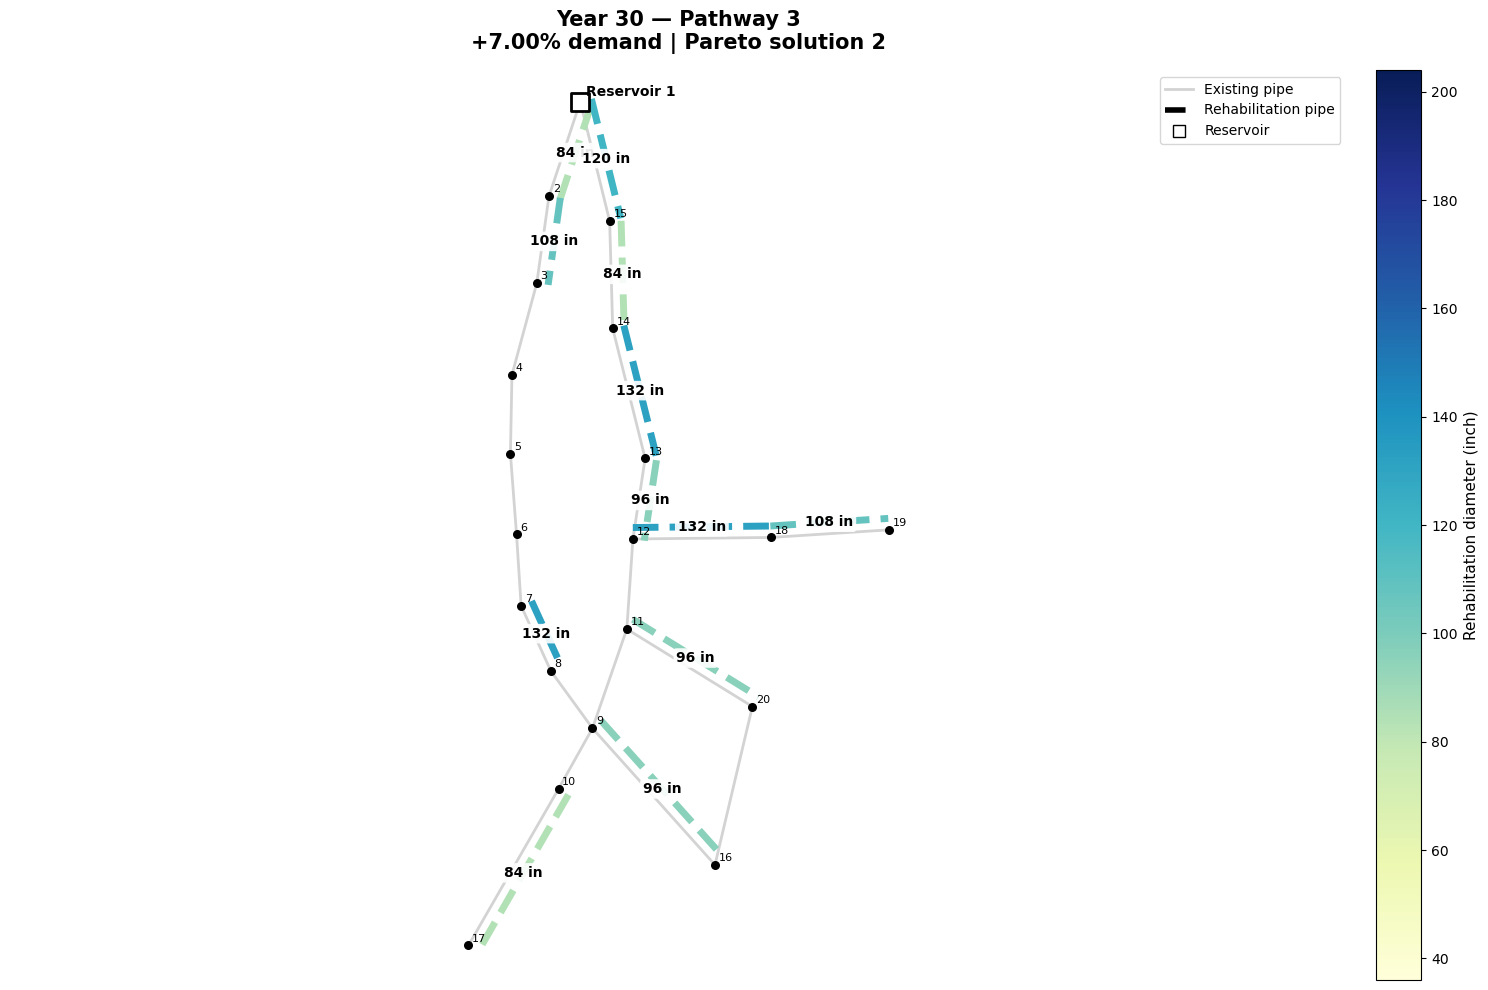

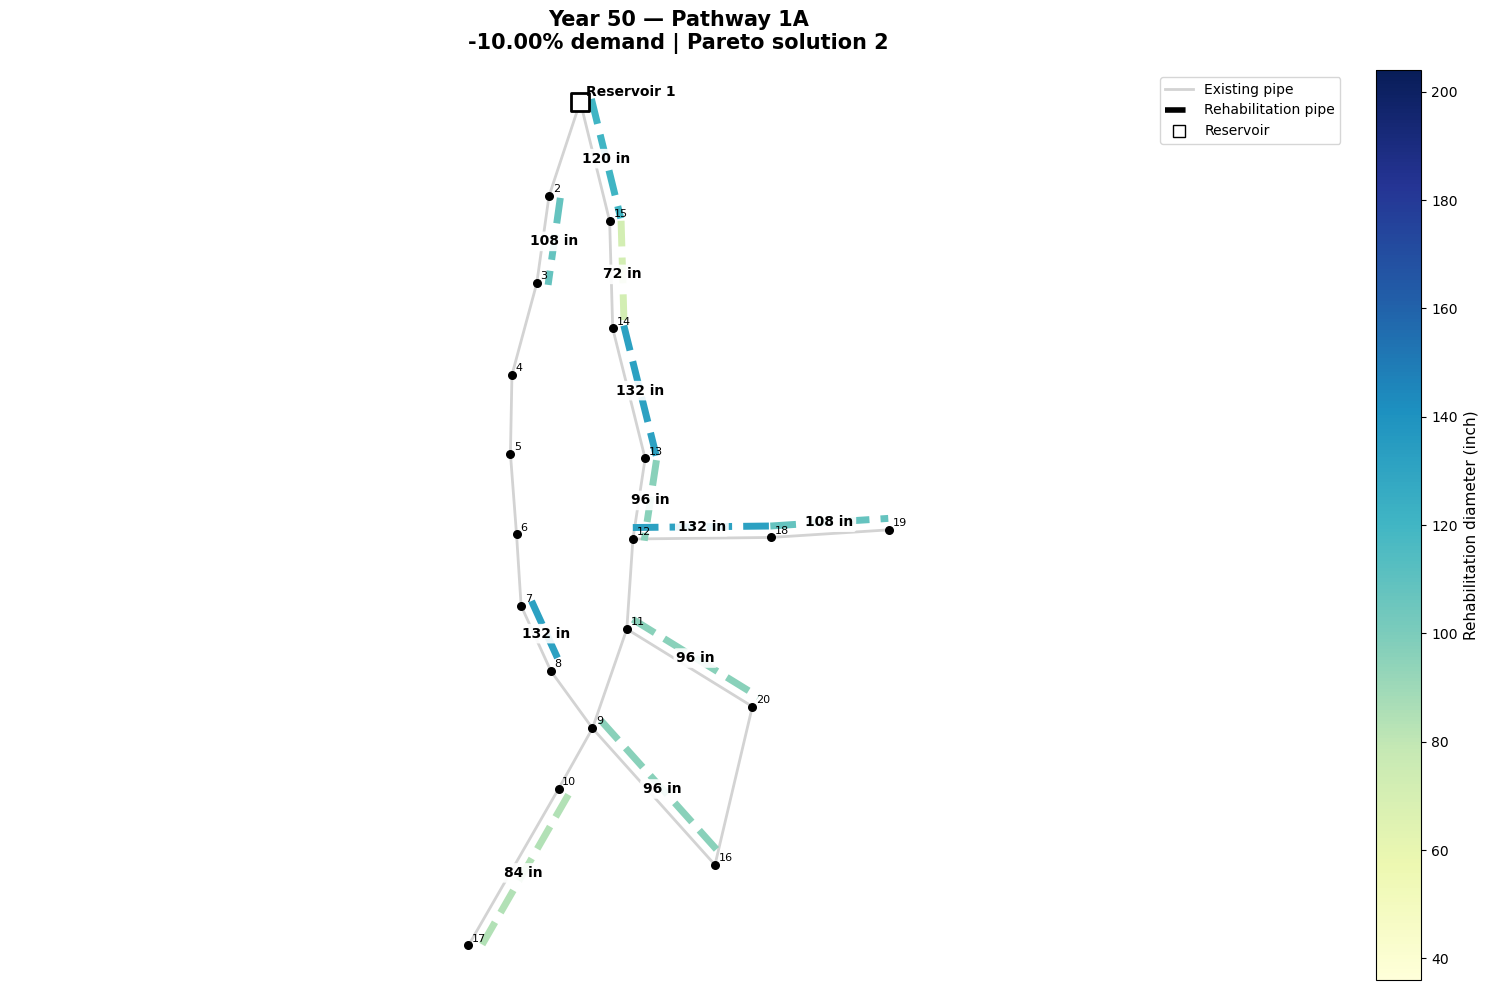

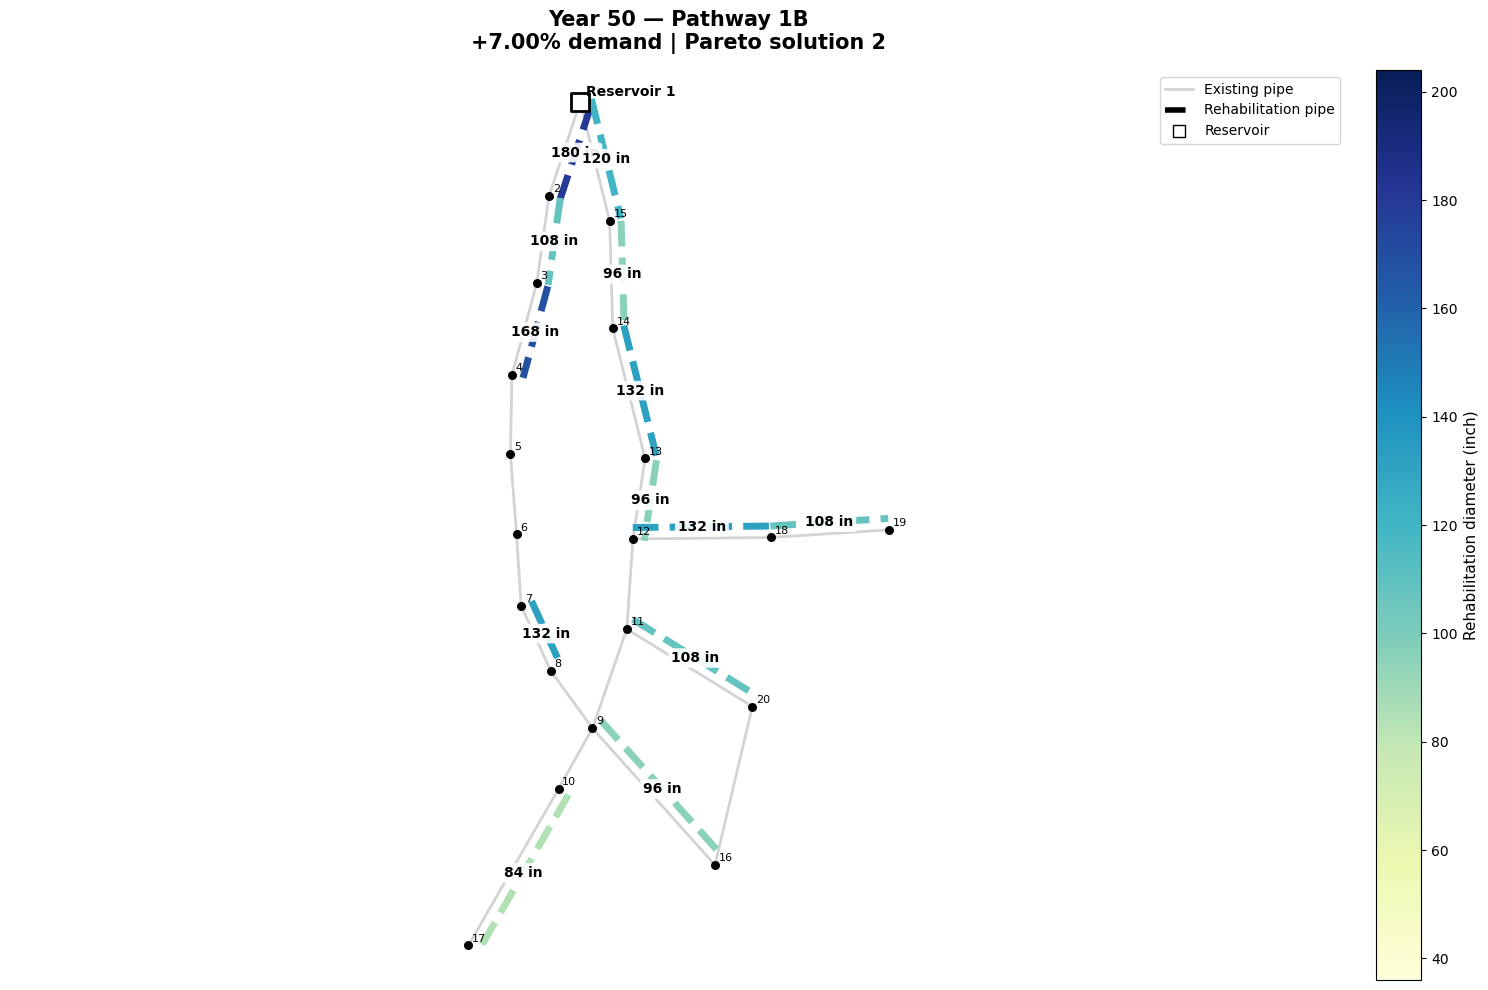

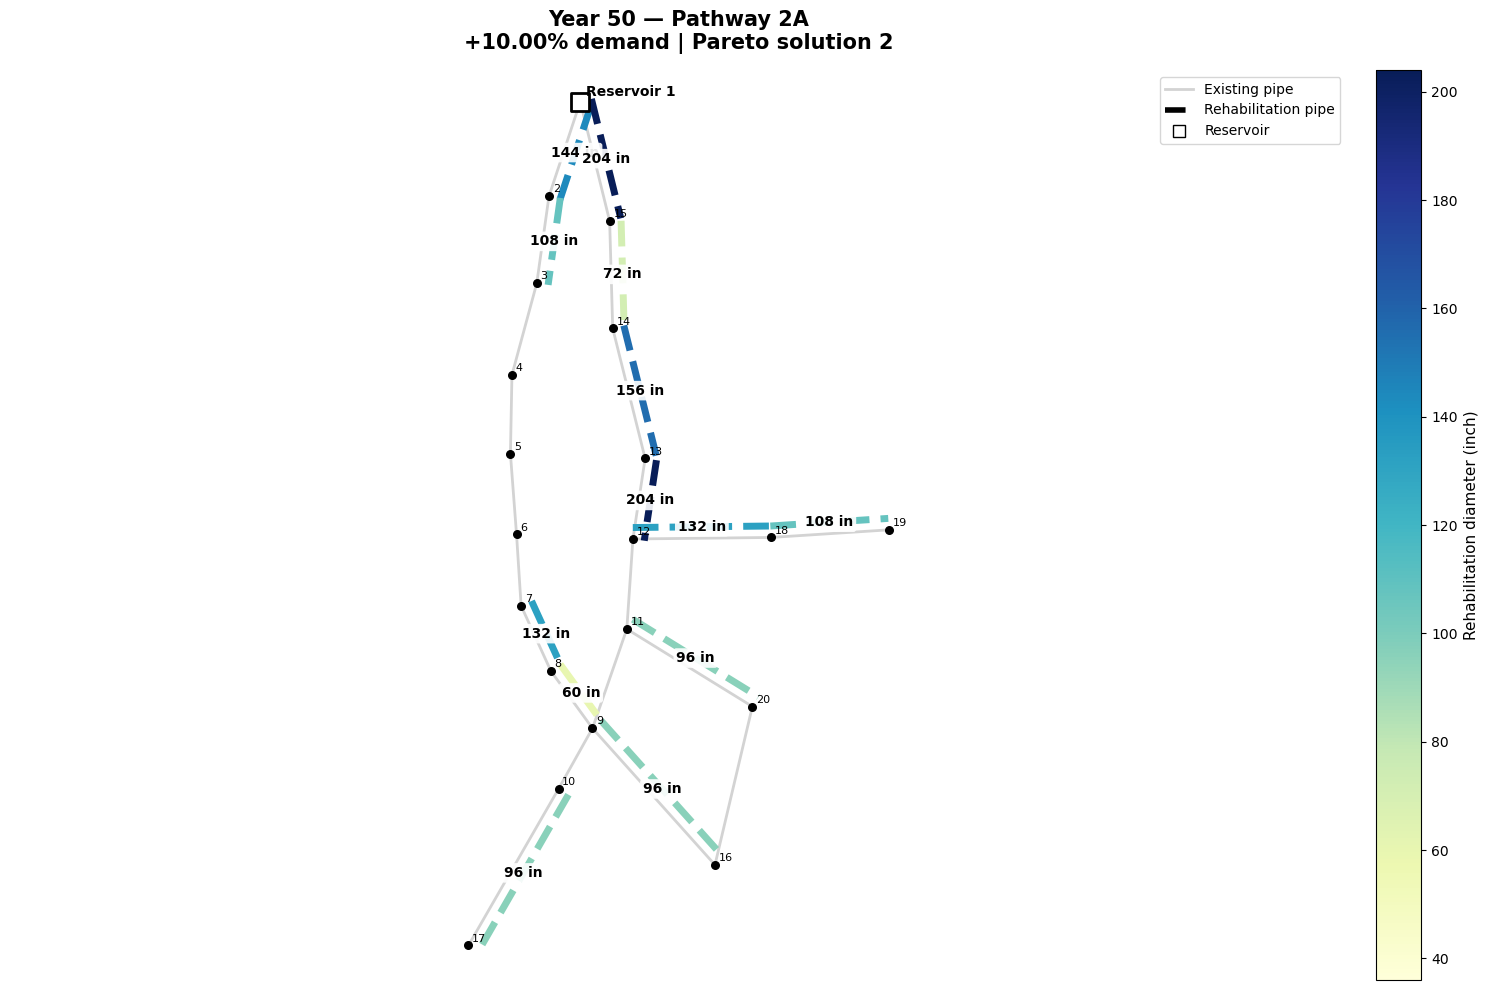

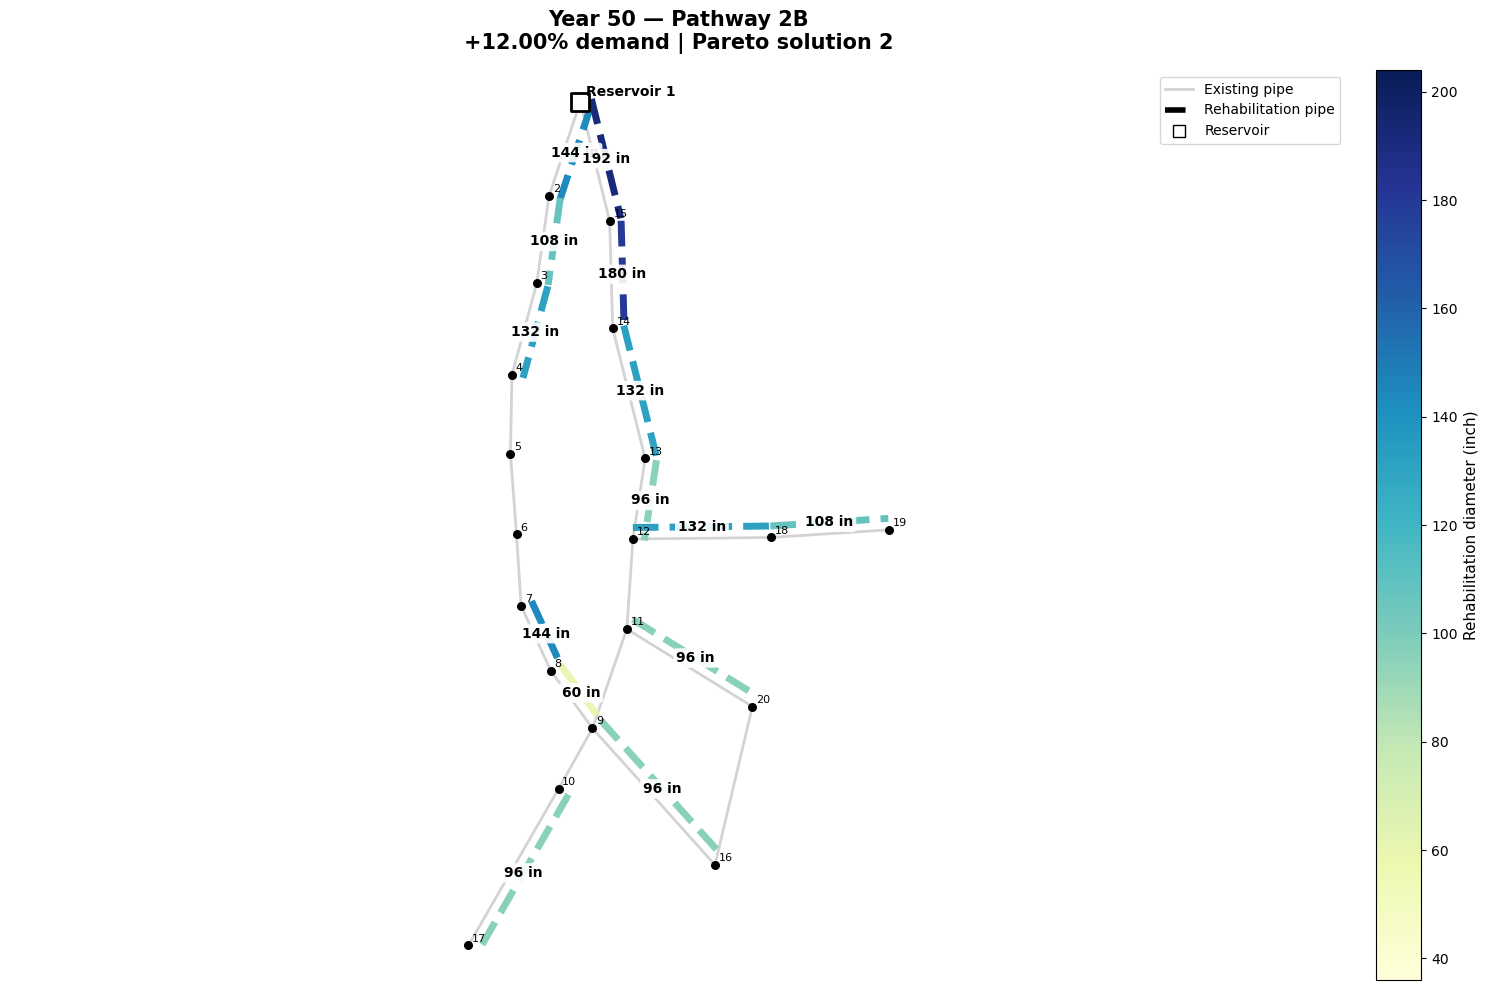

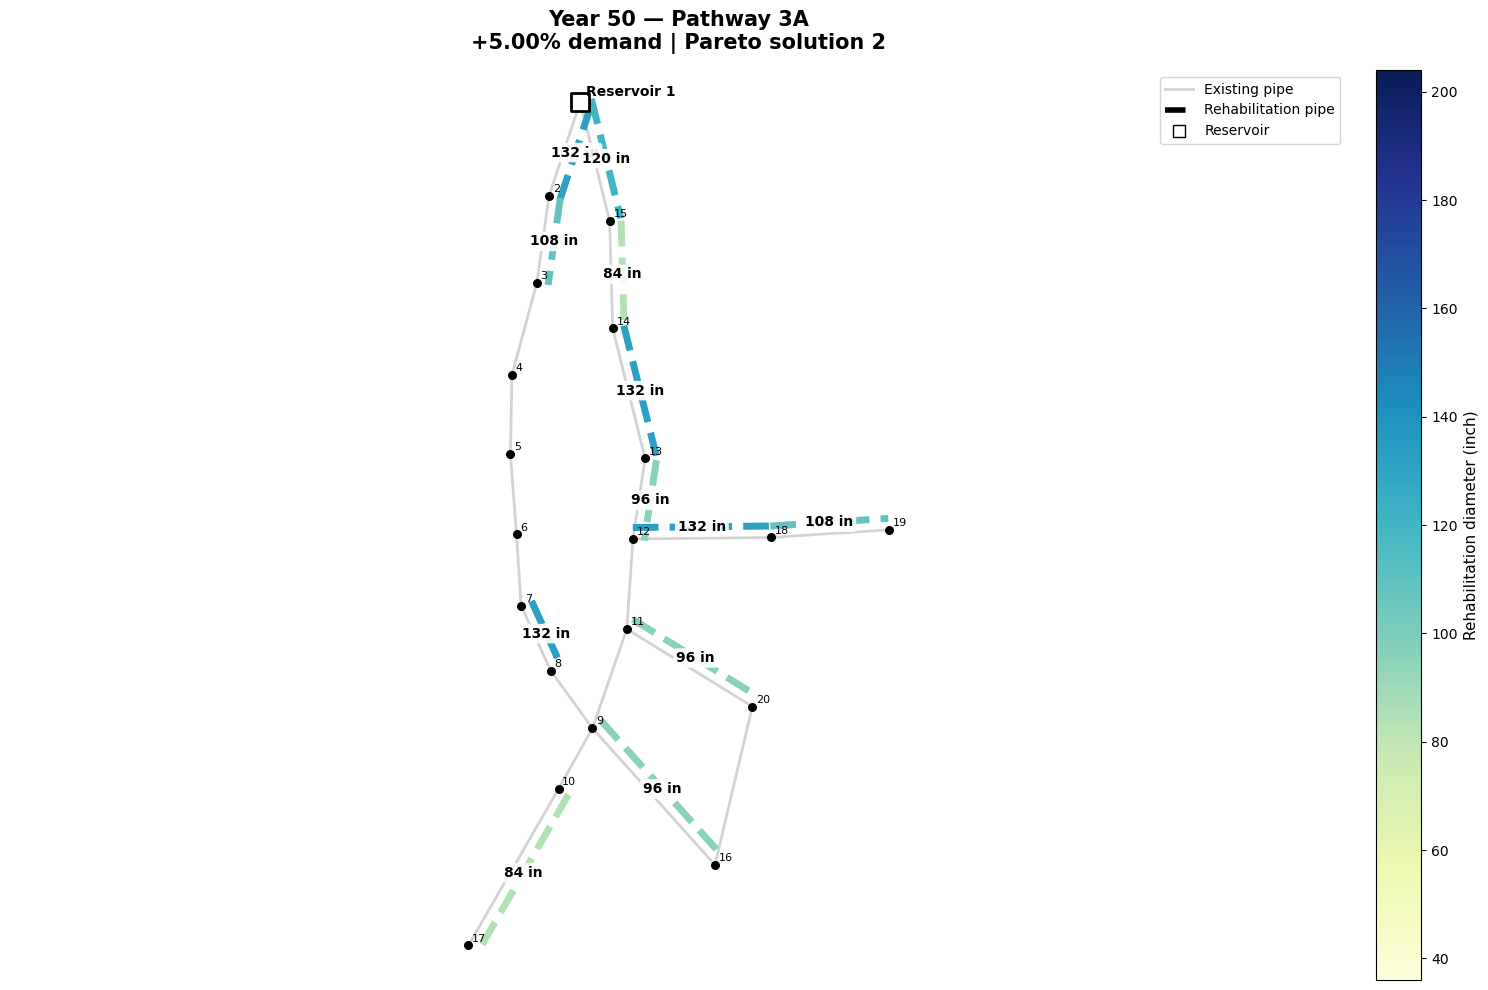

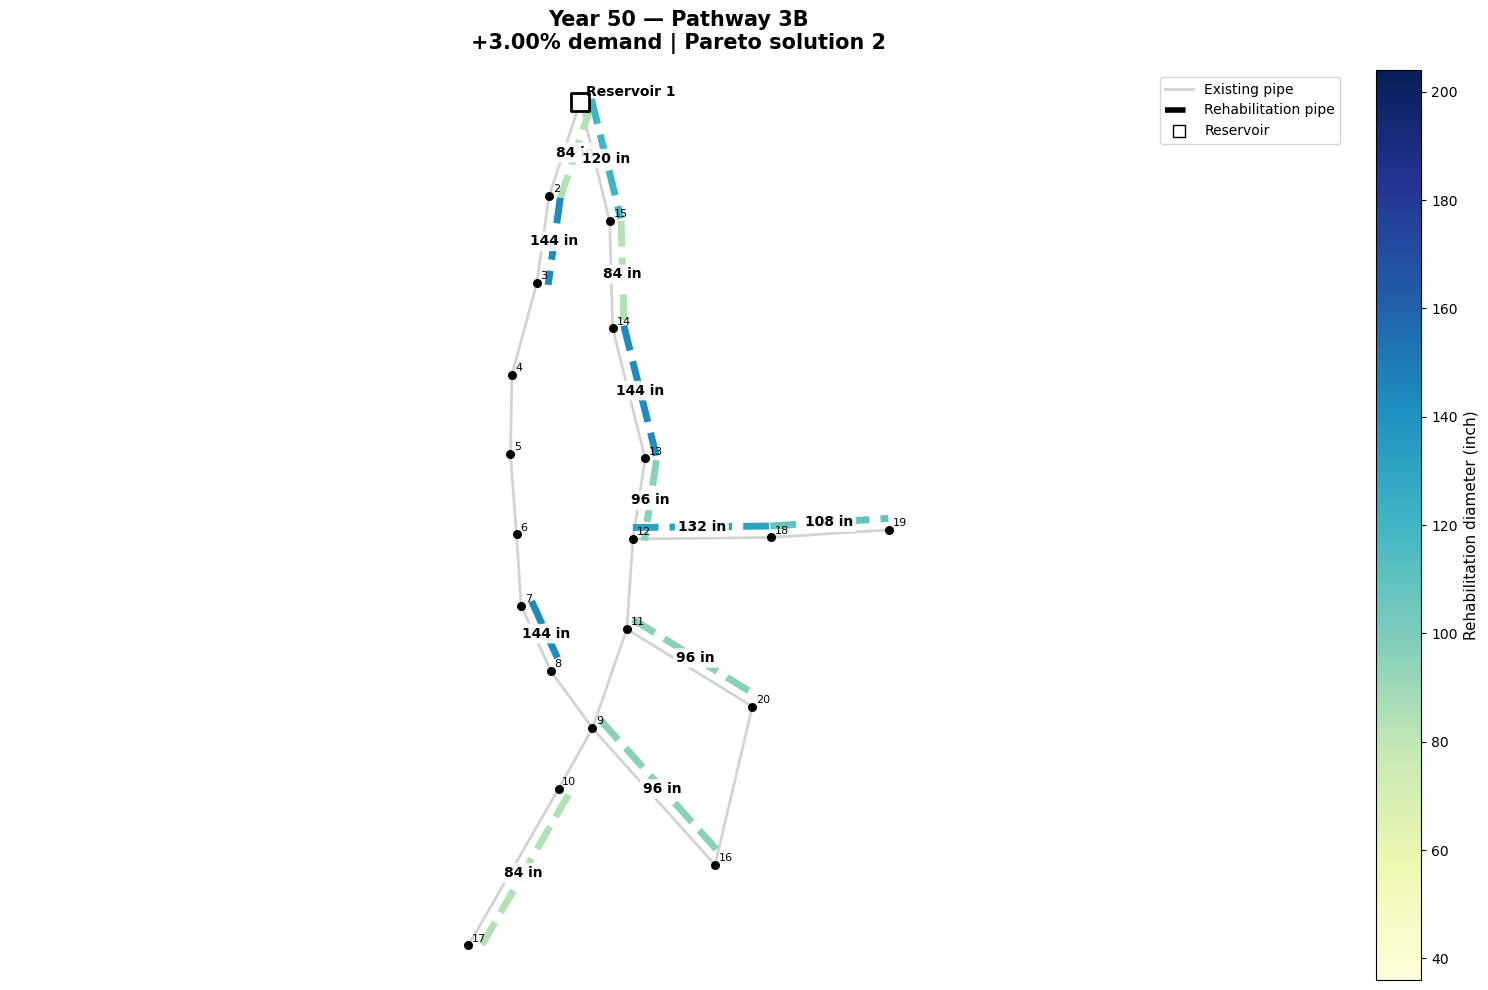


ACTUAL REHABILITATION OPTIONS — SELECTED TREE

Year 15 — Common decision:
[0 7 0 0 0 0 9 0 0 0 0 6 9 4 8 5 9 7 6 0 6]

Year 30 — Pathway 1:
[0 7 0 0 0 0 9 0 0 0 0 6 9 4 8 5 9 7 6 0 6]

Year 30 — Pathway 2:
[10  7  0  0  0  0  9  3  0  0  0  6  9  4  8  6  9  7  6  0  6]

Year 30 — Pathway 3:
[5 7 0 0 0 0 9 0 0 0 0 6 9 5 8 5 9 7 6 0 6]

Year 50 — Pathway 1A:
[0 7 0 0 0 0 9 0 0 0 0 6 9 4 8 5 9 7 6 0 6]

Year 50 — Pathway 1B:
[13  7 12  0  0  0  9  0  0  0  0  6  9  6  8  5  9  7  7  0  6]

Year 50 — Pathway 2A:
[10  7  0  0  0  0  9  3  0  0  0 15 11  4 15  6  9  7  6  0  6]

Year 50 — Pathway 2B:
[10  7  9  0  0  0 10  3  0  0  0  6  9 13 14  6  9  7  6  0  6]

Year 50 — Pathway 3A:
[9 7 0 0 0 0 9 0 0 0 0 6 9 5 8 5 9 7 6 0 6]

Year 50 — Pathway 3B:
[ 5 10  0  0  0  0 10  0  0  0  0  6 10  5  8  5  9  7  6  0  6]

All 10 network figures generated.


In [29]:

# ============================================================
# NYT FULL FLEXIBLE TREE — NETWORK VISUALISATION
#
# Year 15: ONE COMMON DECISION
# Year 30: Pathways 1, 2, 3
# Year 50: Two leaves for each pathway
#
# Requires:
#   - res
#   - problem
#
# Run after the full-tree optimisation.
# ============================================================

import copy
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.lines import Line2D
import wntr


# ============================================================
# 1. USER SETTINGS
# ============================================================

# Default: lowest-cost Pareto solution.
# Change this to another valid index if required.
solution_number = int(np.argmin(res.F[:, 0]))

# Save all figures as high-resolution PNG files?
save_figures = False

output_folder = "NYT_Flexible_Tree_Plots"


# ============================================================
# 2. LOAD ORIGINAL NETWORK
# ============================================================

inp_file = problem.inp_file

wn_original = wntr.network.WaterNetworkModel(inp_file)

pipe_names = list(wn_original.pipe_name_list)
n_pipes = len(pipe_names)

diameter_options = np.array([
    0, 36, 48, 60, 72, 84, 96, 108,
    120, 132, 144, 156, 168, 180, 192, 204
])

MAX_OPTION = len(diameter_options) - 1


# ============================================================
# 3. COMMON YEAR 15 DECISION
# ============================================================

year15_common = np.array([
    0, 7, 0, 0, 0, 0, 9, 0, 0, 0, 0,
    6, 9, 4, 8, 5, 9, 7, 6, 0, 6
], dtype=int)

if len(year15_common) != n_pipes:
    raise ValueError(
        f"Year 15 has {len(year15_common)} values, "
        f"but the network has {n_pipes} candidate pipes."
    )


# ============================================================
# 4. SELECT PARETO SOLUTION
# ============================================================

if res.X is None or len(res.X) == 0:
    raise ValueError("No optimisation solutions found.")

if not 0 <= solution_number < len(res.X):
    raise ValueError("Selected solution index is out of range.")

x_selected = np.rint(res.X[solution_number]).astype(int)

expected_length = 9 * n_pipes

if len(x_selected) != expected_length:
    raise ValueError(
        f"Expected {expected_length} variables "
        f"(9 blocks x {n_pipes} pipes), "
        f"received {len(x_selected)}."
    )

# The optimiser stores increments, not absolute options.
increments = x_selected.reshape(9, n_pipes)

print("=" * 65)
print("SELECTED FLEXIBLE-TREE SOLUTION")
print("=" * 65)
print(f"Solution index: {solution_number}")
print(f"PV cost: {res.F[solution_number, 0]:.6f} million")
print(f"Average resilience: {-res.F[solution_number, 1]:.6f}")
print(f"Candidate pipes: {n_pipes}")


# ============================================================
# 5. CONVERT INCREMENTS INTO ACTUAL OPTIONS
# ============================================================

def apply_increment(previous_options, increment_options):
    """
    Convert a non-negative option-index increment into
    the actual rehabilitation option.

    Example:
        Previous option = 7
        Increment = 2
        Actual option = 9

    Options are capped at the maximum available index.
    """

    previous_options = np.rint(previous_options).astype(int)

    increments_nonnegative = np.maximum(
        np.rint(increment_options).astype(int),
        0
    )

    actual_options = previous_options + increments_nonnegative

    return np.clip(
        actual_options, 0, MAX_OPTION
    ).astype(int)


# Chromosome block order:
# 0: Year30 P1
# 1: Year30 P2
# 2: Year30 P3
# 3: Year50 P1A
# 4: Year50 P1B
# 5: Year50 P2A
# 6: Year50 P2B
# 7: Year50 P3A
# 8: Year50 P3B

year30_p1 = apply_increment(year15_common, increments[0])
year30_p2 = apply_increment(year15_common, increments[1])
year30_p3 = apply_increment(year15_common, increments[2])

year50_p1a = apply_increment(year30_p1, increments[3])
year50_p1b = apply_increment(year30_p1, increments[4])

year50_p2a = apply_increment(year30_p2, increments[5])
year50_p2b = apply_increment(year30_p2, increments[6])

year50_p3a = apply_increment(year30_p3, increments[7])
year50_p3b = apply_increment(year30_p3, increments[8])


# ============================================================
# 6. DEFINE SCENARIO TREE AND CUMULATIVE DEMAND FACTORS
# ============================================================

# Demand factors are relative to the original baseline:
#
# Year 15: 1.00
#
# Pathway 1:
#   Year 30 = 0.95
#   Year 50A = 0.855
#   Year 50B = 1.0165
#
# Pathway 2:
#   Year 30 = 1.05
#   Year 50A = 1.155
#   Year 50B = 1.176
#
# Pathway 3:
#   Year 30 = 1.07
#   Year 50A = 1.1235
#   Year 50B = 1.1021
#
# Labels at Year 50 will show the change relative to
# the corresponding Year 30 parent, NOT baseline.


stages = [
    {
        "name": "Year 15 — Common decision",
        "year": 15,
        "path": "Common",
        "demand": 1.00,
        "options": year15_common,
        "parent": None
    },
    {
        "name": "Year 30 — Pathway 1",
        "year": 30,
        "path": "Pathway 1",
        "demand": 0.95,
        "options": year30_p1,
        "parent": 0
    },
    {
        "name": "Year 30 — Pathway 2",
        "year": 30,
        "path": "Pathway 2",
        "demand": 1.05,
        "options": year30_p2,
        "parent": 0
    },
    {
        "name": "Year 30 — Pathway 3",
        "year": 30,
        "path": "Pathway 3",
        "demand": 1.07,
        "options": year30_p3,
        "parent": 0
    },
    {
        "name": "Year 50 — Pathway 1A",
        "year": 50,
        "path": "Pathway 1A",
        "demand": 0.855,
        "options": year50_p1a,
        "parent": 1
    },
    {
        "name": "Year 50 — Pathway 1B",
        "year": 50,
        "path": "Pathway 1B",
        "demand": 1.0165,
        "options": year50_p1b,
        "parent": 1
    },
    {
        "name": "Year 50 — Pathway 2A",
        "year": 50,
        "path": "Pathway 2A",
        "demand": 1.155,
        "options": year50_p2a,
        "parent": 2
    },
    {
        "name": "Year 50 — Pathway 2B",
        "year": 50,
        "path": "Pathway 2B",
        "demand": 1.176,
        "options": year50_p2b,
        "parent": 2
    },
    {
        "name": "Year 50 — Pathway 3A",
        "year": 50,
        "path": "Pathway 3A",
        "demand": 1.1235,
        "options": year50_p3a,
        "parent": 3
    },
    {
        "name": "Year 50 — Pathway 3B",
        "year": 50,
        "path": "Pathway 3B",
        "demand": 1.1021,
        "options": year50_p3b,
        "parent": 3
    }
]


# ============================================================
# 7. BUILD NETWORKS ALONG THE TREE
# ============================================================

def apply_rehabilitation(wn, absolute_options):
    """
    Apply the actual rehabilitation options for one stage.

    Each option > 0 creates or replaces a parallel pipe.
    """

    for i, pipe_name in enumerate(pipe_names):

        option = int(absolute_options[i])

        if option == 0:
            continue

        diameter_in = diameter_options[option]
        parallel_name = f"{pipe_name}_parallel"

        original_pipe = wn.get_link(pipe_name)

        if parallel_name in wn.link_name_list:
            wn.remove_link(parallel_name)

        wn.add_pipe(
            name=parallel_name,
            start_node_name=original_pipe.start_node_name,
            end_node_name=original_pipe.end_node_name,
            length=original_pipe.length,
            diameter=diameter_in * 0.0254,
            roughness=original_pipe.roughness
        )

    return wn


stage_networks = []

for stage_index, stage in enumerate(stages):

    if stage["parent"] is None:
        # Year 15 starts from the original network.
        wn_stage = copy.deepcopy(wn_original)
    else:
        # Later stages inherit their own parent network.
        wn_stage = copy.deepcopy(
            stage_networks[stage["parent"]]
        )

    wn_stage = apply_rehabilitation(
        wn_stage,
        stage["options"]
    )

    stage_networks.append(wn_stage)


# ============================================================
# 8. COORDINATES AND CONSISTENT COLOUR SCALE
# ============================================================

coordinates = {}

for node_name in wn_original.node_name_list:

    node = wn_original.get_node(node_name)

    if node.coordinates is not None:
        coordinates[node_name] = tuple(node.coordinates)

norm = mpl.colors.Normalize(vmin=36, vmax=204)
cmap = plt.cm.YlGnBu


# ============================================================
# 9. PLOTTING FUNCTION
# ============================================================

def plot_stage(stage, wn):

    fig, ax = plt.subplots(figsize=(15, 10))

    # --------------------------------------------------------
    # ORIGINAL PIPES
    # --------------------------------------------------------

    for pipe_name in pipe_names:

        pipe = wn_original.get_link(pipe_name)

        start_name = pipe.start_node_name
        end_name = pipe.end_node_name

        if (
            start_name not in coordinates
            or end_name not in coordinates
        ):
            continue

        start = np.array(coordinates[start_name], dtype=float)
        end = np.array(coordinates[end_name], dtype=float)

        ax.plot(
            [start[0], end[0]],
            [start[1], end[1]],
            color="lightgray",
            linewidth=2,
            zorder=1
        )

    # --------------------------------------------------------
    # REHABILITATION PIPES
    # --------------------------------------------------------

    for i, pipe_name in enumerate(pipe_names):

        option = int(stage["options"][i])

        if option == 0:
            continue

        parallel_name = f"{pipe_name}_parallel"

        if parallel_name not in wn.link_name_list:
            continue

        pipe = wn.get_link(parallel_name)

        start_name = pipe.start_node_name
        end_name = pipe.end_node_name

        if (
            start_name not in coordinates
            or end_name not in coordinates
        ):
            continue

        start = np.array(coordinates[start_name], dtype=float)
        end = np.array(coordinates[end_name], dtype=float)

        dx, dy = end - start
        length = np.hypot(dx, dy)

        if length == 0:
            continue

        # Offset parallel rehabilitation pipe for visibility.
        perpendicular = np.array([-dy, dx]) / length
        offset = 30

        start_offset = start + perpendicular * offset
        end_offset = end + perpendicular * offset

        diameter_in = diameter_options[option]
        pipe_color = cmap(norm(diameter_in))

        ax.plot(
            [start_offset[0], end_offset[0]],
            [start_offset[1], end_offset[1]],
            linestyle="--",
            linewidth=5,
            color=pipe_color,
            zorder=4
        )

        midpoint = (start_offset + end_offset) / 2

        ax.text(
            midpoint[0],
            midpoint[1],
            f"{diameter_in} in",
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="center",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                alpha=0.9,
                edgecolor="none"
            ),
            zorder=6
        )

    # --------------------------------------------------------
    # JUNCTIONS AND LABELS
    # --------------------------------------------------------

    for node_name in wn_original.junction_name_list:

        if node_name not in coordinates:
            continue

        x_coord, y_coord = coordinates[node_name]

        ax.scatter(
            x_coord, y_coord,
            s=30, color="black", zorder=7
        )

        ax.text(
            x_coord + 10,
            y_coord + 10,
            str(node_name),
            fontsize=8,
            zorder=8
        )

    # --------------------------------------------------------
    # RESERVOIR
    # --------------------------------------------------------

    for reservoir_name in wn_original.reservoir_name_list:

        if reservoir_name not in coordinates:
            continue

        x_coord, y_coord = coordinates[reservoir_name]

        ax.scatter(
            x_coord, y_coord,
            s=180,
            marker="s",
            facecolor="white",
            edgecolor="black",
            linewidth=2,
            zorder=9
        )

        ax.text(
            x_coord + 15,
            y_coord + 15,
            f"Reservoir {reservoir_name}",
            fontsize=10,
            fontweight="bold",
            zorder=10
        )

    # --------------------------------------------------------
    # COLOUR BAR
    # --------------------------------------------------------

    sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    sm.set_array([])

    cbar = fig.colorbar(
        sm, ax=ax,
        fraction=0.035,
        pad=0.02
    )

    cbar.set_label(
        "Rehabilitation diameter (inch)",
        fontsize=11
    )

    # --------------------------------------------------------
    # LEGEND
    # --------------------------------------------------------

    legend_handles = [
        Line2D(
            [0], [0],
            color="lightgray",
            linewidth=2,
            label="Existing pipe"
        ),
        Line2D(
            [0], [0],
            color="black",
            linewidth=4,
            linestyle="--",
            label="Rehabilitation pipe"
        ),
        Line2D(
            [0], [0],
            marker="s",
            color="black",
            markerfacecolor="white",
            markersize=9,
            linestyle="None",
            label="Reservoir"
        )
    ]

    ax.legend(
        handles=legend_handles,
        loc="upper right",
        fontsize=10,
        frameon=True
    )

    # --------------------------------------------------------
    # CORRECT DEMAND LABEL: CHANGE FROM PARENT
    # --------------------------------------------------------

    if stage["parent"] is None:

        demand_text = "Baseline demand"

    else:

        parent_factor = stages[stage["parent"]]["demand"]

        demand_percent = (
            stage["demand"] / parent_factor - 1
        ) * 100

        demand_text = f"{demand_percent:+.2f}% demand"

    ax.set_title(
        f"{stage['name']}\n"
        f"{demand_text} | Pareto solution {solution_number}",
        fontsize=15,
        fontweight="bold",
        pad=15
    )

    # --------------------------------------------------------
    # CLEAN LAYOUT
    # --------------------------------------------------------

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

    ax.set_facecolor("white")
    fig.patch.set_facecolor("white")
    ax.set_aspect("equal", adjustable="datalim")

    plt.tight_layout()

    # --------------------------------------------------------
    # OPTIONAL HIGH-RESOLUTION EXPORT
    # --------------------------------------------------------

    if save_figures:

        os.makedirs(output_folder, exist_ok=True)

        safe_name = (
            stage["name"]
            .replace(" ", "_")
            .replace("—", "-")
        )

        filepath = os.path.join(
            output_folder,
            f"{safe_name}.png"
        )

        fig.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        print("Saved:", filepath)

    plt.show()


# ============================================================
# 10. GENERATE ALL 10 FIGURES
# ============================================================

for stage, wn_stage in zip(stages, stage_networks):
    plot_stage(stage, wn_stage)


# ============================================================
# 11. PRINT ACTUAL REHABILITATION OPTIONS
# ============================================================

print("\n" + "=" * 65)
print("ACTUAL REHABILITATION OPTIONS — SELECTED TREE")
print("=" * 65)

for stage in stages:
    print(f"\n{stage['name']}:")
    print(stage["options"])

print("\nAll 10 network figures generated.")


In [1]:

# ============================================================
# FINAL HYDRAULIC FEASIBILITY VERIFICATION
#
# Checks all 10 states:
#   1. Year 15 common
#   2. Year 30 Pathways 1, 2, 3
#   3. Year 50 Pathways 1A, 1B, 2A, 2B, 3A, 3B
#
# Requires variables from the plotting cell:
#   wn_original, pipe_names, diameter_options
#   year15_common, year30_p1, year30_p2, year30_p3
#   year50_p1a, year50_p1b, year50_p2a, year50_p2b
#   year50_p3a, year50_p3b
# ============================================================

import copy
import numpy as np
import pandas as pd
import wntr


# ============================================================
# 1. REQUIRED HEADS — FEET
# ============================================================

required_head_ft = {
    **{str(i): 255.0 for i in range(2, 16)},
    "16": 260.0,
    "17": 272.8,
    "18": 255.0,
    "19": 255.0,
    "20": 255.0
}


# ============================================================
# 2. DEFINE ALL 10 STATES
# ============================================================

verification_stages = [
    ("Year 15 — Common", 1.00, year15_common),
    ("Year 30 — Pathway 1", 0.95, year30_p1),
    ("Year 30 — Pathway 2", 1.05, year30_p2),
    ("Year 30 — Pathway 3", 1.07, year30_p3),
    ("Year 50 — Pathway 1A", 0.855, year50_p1a),
    ("Year 50 — Pathway 1B", 1.0165, year50_p1b),
    ("Year 50 — Pathway 2A", 1.155, year50_p2a),
    ("Year 50 — Pathway 2B", 1.176, year50_p2b),
    ("Year 50 — Pathway 3A", 1.1235, year50_p3a),
    ("Year 50 — Pathway 3B", 1.1021, year50_p3b),
]


# ============================================================
# 3. HELPER: APPLY DEMAND FACTOR
# ============================================================

def set_demand_factor(wn, factor):
    """
    Scale each junction's original base demand by the
    scenario factor. Each state starts from a fresh network.
    """
    for node_name in wn.junction_name_list:
        node = wn.get_node(node_name)

        for demand in node.demand_timeseries_list:
            demand.base_value *= factor


# ============================================================
# 4. HELPER: APPLY REHABILITATION
# ============================================================

def apply_rehabilitation_for_check(wn, options):
    """
    Recreate the rehabilitation pipes from the selected
    absolute option vector, matching the plotting logic.
    """
    for i, pipe_name in enumerate(pipe_names):
        option = int(options[i])

        if option == 0:
            continue

        diameter_in = diameter_options[option]
        parallel_name = f"{pipe_name}_parallel"

        original_pipe = wn.get_link(pipe_name)

        if parallel_name in wn.link_name_list:
            wn.remove_link(parallel_name)

        wn.add_pipe(
            name=parallel_name,
            start_node_name=original_pipe.start_node_name,
            end_node_name=original_pipe.end_node_name,
            length=original_pipe.length,
            diameter=diameter_in * 0.0254,
            roughness=original_pipe.roughness
        )

    return wn


# ============================================================
# 5. RUN EACH HYDRAULIC STATE AND CHECK HEADS
# ============================================================

all_node_results = []
stage_summary = []

print("=" * 90)
print("HYDRAULIC FEASIBILITY CHECK — ALL 10 STATES")
print("=" * 90)

for stage_name, demand_factor, options in verification_stages:

    # Always start from the original network.
    wn_check = copy.deepcopy(wn_original)

    # Apply scenario demand and the complete rehabilitation
    # configuration for this stage.
    set_demand_factor(wn_check, demand_factor)
    apply_rehabilitation_for_check(wn_check, options)

    try:
        # Run EPANET hydraulics.
        sim = wntr.sim.EpanetSimulator(wn_check)
        results = sim.run_sim()

        # Use the first simulated timestep, matching the
        # steady-state evaluation used in the optimisation.
        heads = results.node["head"].iloc[0]

        margins = []

        for node_name, required_ft in required_head_ft.items():

            if node_name not in heads.index:
                raise KeyError(
                    f"Required node {node_name} is missing "
                    f"from the hydraulic results."
                )

            # EPANET/WNTR heads are in metres for this model.
            simulated_head_m = float(heads[node_name])
            simulated_head_ft = simulated_head_m / 0.3048

            margin_ft = simulated_head_ft - required_ft
            margins.append(margin_ft)

            all_node_results.append({
                "Stage": stage_name,
                "Node": node_name,
                "Required head (ft)": required_ft,
                "Simulated head (ft)": simulated_head_ft,
                "Head margin (ft)": margin_ft,
                "Feasible": margin_ft >= -1e-4
            })

        minimum_margin = min(margins)
        limiting_index = int(np.argmin(margins))
        limiting_node = list(required_head_ft.keys())[limiting_index]

        feasible = minimum_margin >= -1e-4

        stage_summary.append({
            "Stage": stage_name,
            "Demand factor": demand_factor,
            "Minimum margin (ft)": minimum_margin,
            "Limiting node": limiting_node,
            "Feasible": feasible
        })

        status = "PASS" if feasible else "FAIL"

        print(
            f"{status:4s} | {stage_name:27s} | "
            f"Minimum margin = {minimum_margin:9.4f} ft | "
            f"Limiting node = {limiting_node}"
        )

    except Exception as exc:
        stage_summary.append({
            "Stage": stage_name,
            "Demand factor": demand_factor,
            "Minimum margin (ft)": np.nan,
            "Limiting node": "Simulation error",
            "Feasible": False
        })

        print(f"ERROR | {stage_name}: {exc}")


# ============================================================
# 6. DISPLAY DETAILED RESULTS
# ============================================================

summary_df = pd.DataFrame(stage_summary)
node_df = pd.DataFrame(all_node_results)

print("\n" + "=" * 90)
print("SUMMARY — MINIMUM HEAD MARGIN PER STAGE")
print("=" * 90)

display(summary_df.round(4))


print("\n" + "=" * 90)
print("NODE-BY-NODE RESULTS")
print("=" * 90)

display(
    node_df.sort_values(["Stage", "Node"]).round(4)
)


# ============================================================
# 7. IDENTIFY ANY VIOLATIONS
# ============================================================

violations_df = node_df.loc[
    ~node_df["Feasible"]
].copy()

if summary_df["Feasible"].all() and len(node_df) == 10 * len(required_head_ft):

    print("\nALL 10 STATES PASSED THE REQUIRED-HEAD CHECK.")
    print("Every required node meets its minimum head.")

elif len(violations_df) > 0:

    print("\nHYDRAULIC HEAD VIOLATIONS FOUND:")
    display(violations_df.round(4))

else:
    print(
        "\nCHECK NOT FULLY PASSED. Inspect the stage summary "
        "for simulation errors or missing results."
    )


NameError: name 'year15_common' is not defined